
# GP / BoTorch Structured Regression Evaluation Notebook

This notebook evaluates a **structured regression** problem where each geometry (sample) has repeated rows for multiple `a_matrix` positions.

## Assumed dataset structure
- **First 20 columns**: geometry parameters (one geometry repeated across all its positions)
- **Columns 21-22**: `a_matrix` position identifiers (for example, matrix row/column or 2D index)
- **Column 23**: target coefficient value

You mentioned you have **separate train, validation, and test datasets**, and predictions already exist for each split.

This notebook evaluates the model at multiple levels:
1. **Global / row-wise regression quality**
2. **Sample-wise / geometry-wise quality** (entire 120-position response per geometry)
3. **Position-wise quality** (which matrix locations are hard to predict)
4. **Distribution / regime analysis** (relative error, log error, target bins, uncertainty bins)
5. **GP uncertainty quality** (if predictive standard deviation is available)
6. **Engineering insights** such as peak-position accuracy and geometry-error relationships


In [2]:
from pxd.datasets.hdf5.directory import HDF5DirectoryDataset, HDF5DirectoryDatasetConfig
import seaborn as sns
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import erf
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score
)
import pandas as pd
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)
sns.set_context('notebook')

In [24]:
train_df

,geometry_parameter_a_1,geometry_parameter_a_2,geometry_parameter_a_3,geometry_parameter_a_4,geometry_parameter_a_5,geometry_parameter_a_6,geometry_parameter_a_7,geometry_parameter_a_8,geometry_parameter_a_9,geometry_parameter_a_10,geometry_parameter_a_11,geometry_parameter_a_12,geometry_parameter_a_13,geometry_parameter_a_14,geometry_parameter_a_15,geometry_parameter_a_16,geometry_parameter_a_17,geometry_parameter_a_18,geometry_parameter_a_19,geometry_parameter_a_20,a_matrix_coeff_position_1,a_matrix_coeff_position_2,a_matrix_coefficient,a_matrix_coefficients_pred,a_matrix_coefficients_pred_stddev
0,1.333101,1.383030,0.351843,0.052289,4.002793,2.238493,2.793808,0.871535,2.729623,0.167227,0.458103,0.292032,0.181636,0.710602,1.741910,0.579850,1.627380,0.207885,0.188176,0.007309,0.0,1.0,0.133590,0.163813,0.172808
1,1.333101,1.383030,0.351843,0.052289,4.002793,2.238493,2.793808,0.871535,2.729623,0.167227,0.458103,0.292032,0.181636,0.710602,1.741910,0.579850,1.627380,0.207885,0.188176,0.007309,0.0,2.0,21.019383,21.034821,0.312439
2,1.333101,1.383030,0.351843,0.052289,4.002793,2.238493,2.793808,0.871535,2.729623,0.167227,0.458103,0.292032,0.181636,0.710602,1.741910,0.579850,1.627380,0.207885,0.188176,0.007309,0.0,3.0,23.515038,24.467485,14.696888
3,1.333101,1.383030,0.351843,0.052289,4.002793,2.238493,2.793808,0.871535,2.729623,0.167227,0.458103,0.292032,0.181636,0.710602,1.741910,0.579850,1.627380,0.207885,0.188176,0.007309,0.0,4.0,0.188570,0.188420,0.005951
4,1.333101,1.383030,0.351843,0.052289,4.002793,2.238493,2.793808,0.871535,2.729623,0.167227,0.458103,0.292032,0.181636,0.710602,1.741910,0.579850,1.627380,0.207885,0.188176,0.007309,0.0,5.0,0.001265,0.001259,0.005468
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61195,1.236150,1.528138,0.374454,0.124577,1.858245,2.197144,2.528203,1.114220,2.083405,0.194992,0.425198,0.243312,0.278985,0.949832,0.394936,0.855933,1.715343,0.068759,0.063625,0.007782,12.0,14.0,18.265728,18.291230,0.314180
61196,1.236150,1.528138,0.374454,0.124577,1.858245,2.197144,2.528203,1.114220,2.083405,0.194992,0.425198,0.243312,0.278985,0.949832,0.394936,0.855933,1.715343,0.068759,0.063625,0.007782,12.0,15.0,12.215418,11.596169,12.028238
61197,1.236150,1.528138,0.374454,0.124577,1.858245,2.197144,2.528203,1.114220,2.083405,0.194992,0.425198,0.243312,0.278985,0.949832,0.394936,0.855933,1.715343,0.068759,0.063625,0.007782,13.0,14.0,12.089525,12.093101,0.279420
61198,1.236150,1.528138,0.374454,0.124577,1.858245,2.197144,2.528203,1.114220,2.083405,0.194992,0.425198,0.243312,0.278985,0.949832,0.394936,0.855933,1.715343,0.068759,0.063625,0.007782,13.0,15.0,16.531158,16.743312,1.872145


## 1) Configuration

In [3]:

# ==============================
# CONFIGURATION - EDIT THIS CELL
# ==============================

# --- File paths ---
TRAIN_DATA_PATH = r"data/full_train_prediction_botorch_dataset.csv"
VALID_DATA_PATH = r"data/full_test_prediction_botorch_dataset.csv"
TEST_DATA_PATH  = r"data/full_val_prediction_botorch_dataset.csv"

# If predictions are already present inside each dataset, keep this True.
# Otherwise set to False and specify separate prediction files below.
PREDICTIONS_ALREADY_IN_DATA = True


# Only used if PREDICTIONS_ALREADY_IN_DATA = False
TRAIN_PRED_PATH = 'train_predictions.csv'
VALID_PRED_PATH = 'validation_predictions.csv'
TEST_PRED_PATH  = 'test_predictions.csv'


# If separate prediction files are used, choose how to align:
# 'row_order' -> same row order as the corresponding dataset
# 'merge_on_keys' -> merge using key columns listed in MERGE_KEY_COLUMNS
PREDICTION_ALIGNMENT_MODE = 'row_order'  # or 'merge_on_keys'
MERGE_KEY_COLUMNS = None  # e.g. ['sample_id', 'pos_1', 'pos_2']


# --- Dataset column layout ---
# By default assumes:
# first 20 columns = geometry features
# next 2 columns   = position columns
# 23rd column      = target
GEOMETRY_COLS = None  # None -> auto use first 20 columns
POSITION_COLS = None  # None -> auto use columns 21 and 22
TARGET_COL = None     # None -> auto use column 23
INDEX_COL = 0

# Prediction column names
PRED_COL = 'a_matrix_coefficients_pred'
PRED_STD_COL  = 'a_matrix_coefficients_pred_stddev'  # optional; set to None if unavailable

# If the target / predictions can be <= 0, keep a very small epsilon for log metrics
LOG_EPS = 1e-12

# Grouping control for sample-wise analysis.
# If geometry columns are floating-point and duplicate groups should be treated as identical,
# values are rounded before grouping.
GEOMETRY_GROUP_DECIMALS = 12

# Coverage levels for uncertainty evaluation
COVERAGE_LEVELS = (0.50, 0.80, 0.90, 0.95, 0.99)

# Number of bins for regime analysis
N_BINS_TARGET = 5
N_BINS_UNCERTAINTY = 5

# Output directory for saved tables and figures
OUTPUT_DIR = Path('output')
OUTPUT_DIR.mkdir(exist_ok=True)

print('Output directory:', OUTPUT_DIR.resolve())

Output directory: /home/jovyan/stator-devtest-nc-ds2/components/evaluation/output


## 2) Helper functions for loading and validation

In [4]:

def read_table(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'File not found: {path}')

    suffix = path.suffix.lower()
    if suffix == '.csv':
        return pd.read_csv(path, index_col=INDEX_COL)
    elif suffix in ['.xlsx', '.xls']:
        engine = 'openpyxl' if suffix == '.xlsx' else 'xlrd'
        return pd.read_excel(path, engine=engine)
    elif suffix == '.parquet':
        return pd.read_parquet(path)
    else:
        raise ValueError(f'Unsupported file extension: {suffix}')


def infer_column_roles(df, geometry_cols=None, position_cols=None, target_col=None, pred_col=None):
    cols = list(df.columns)
    geometry_cols = geometry_cols if geometry_cols is not None else cols[:20]
    position_cols = position_cols if position_cols is not None else cols[20:22]
    target_col = target_col if target_col is not None else cols[22]
    pred_col = pred_col if pred_col is not None else cols[23]
    return geometry_cols, position_cols, target_col, pred_col


def validate_columns(df, geometry_cols, position_cols, target_col, pred_col, pred_std_col=None):
    required = list(geometry_cols) + list(position_cols) + [target_col, pred_col]
    if pred_std_col is not None:
        required.append(pred_std_col)
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise KeyError(f'Missing required columns: {missing}')

"""
def add_predictions_to_df(df, pred_df, pred_mean_col, pred_std_col=None,
                          alignment_mode='row_order', merge_key_columns=None):
    df = df.copy()
    pred_df = pred_df.copy()

    if alignment_mode == 'row_order':
        if len(df) != len(pred_df):
            raise ValueError(f'Row count mismatch: dataset={len(df)} predictions={len(pred_df)}')
        df[pred_mean_col] = pred_df[pred_mean_col].values
        if pred_std_col is not None and pred_std_col in pred_df.columns:
            df[pred_std_col] = pred_df[pred_std_col].values
    elif alignment_mode == 'merge_on_keys':
        if not merge_key_columns:
            raise ValueError('MERGE_KEY_COLUMNS must be provided when alignment_mode="merge_on_keys"')
        cols_to_merge = list(merge_key_columns) + [pred_mean_col]
        if pred_std_col is not None and pred_std_col in pred_df.columns:
            cols_to_merge.append(pred_std_col)
        df = df.merge(pred_df[cols_to_merge], on=list(merge_key_columns), how='left')
        if df[pred_mean_col].isna().any():
            raise ValueError('Some predictions could not be merged. Check MERGE_KEY_COLUMNS.')
    else:
        raise ValueError(f'Unknown alignment_mode: {alignment_mode}')

    return df
"""

def prepare_split_df(data_path, split_name,
                     geometry_cols=None, position_cols=None, target_col=None,
                     pred_col='a_matrix_coefficients_pred', pred_std_col='a_matrix_coefficients_pred_stddev',
                     predictions_already_in_data=True, pred_path=None,
                     alignment_mode='row_order', merge_key_columns=None):
    df = read_table(data_path)
    geometry_cols, position_cols, target_col, pred_col = infer_column_roles(df, geometry_cols, position_cols, target_col, pred_col)

    if not predictions_already_in_data:
        pred_df = read_table(pred_path)
        df = add_predictions_to_df(
            df, pred_df,
            pred_col=pred_col,
            pred_std_col=pred_std_col,
            alignment_mode=alignment_mode,
            merge_key_columns=merge_key_columns
        )

    validate_columns(df, geometry_cols, position_cols, target_col, pred_col,
                     pred_std_col if pred_std_col in df.columns else None)

    print(f'[{split_name}] shape={df.shape}')
    print(f'[{split_name}] geometry cols = {geometry_cols}')
    print(f'[{split_name}] position cols = {position_cols}')
    print(f'[{split_name}] target col   = {target_col}')
    print(f'[{split_name}] prediction cols present = {[c for c in [pred_col, pred_std_col] if c in df.columns]}')
    return df, geometry_cols, position_cols, target_col, pred_col

In [6]:
y_true_train, y_pred_train = train_df["a_matrix_coefficient"].values,train_df["a_matrix_coefficients_pred"].values
y_true_test, y_pred_test = test_df["a_matrix_coefficient"].values, test_df["a_matrix_coefficients_pred"].values
y_true_val, y_pred_val = val_df["a_matrix_coefficient"].values, val_df["a_matrix_coefficients_pred"].values

In [32]:
test_df.head()

,geometry_parameter_a_1,geometry_parameter_a_2,geometry_parameter_a_3,geometry_parameter_a_4,geometry_parameter_a_5,geometry_parameter_a_6,geometry_parameter_a_7,geometry_parameter_a_8,geometry_parameter_a_9,geometry_parameter_a_10,geometry_parameter_a_11,geometry_parameter_a_12,geometry_parameter_a_13,geometry_parameter_a_14,geometry_parameter_a_15,geometry_parameter_a_16,geometry_parameter_a_17,geometry_parameter_a_18,geometry_parameter_a_19,geometry_parameter_a_20,a_matrix_coeff_position_1,a_matrix_coeff_position_2,a_matrix_coefficient,a_matrix_coefficients_pred,a_matrix_coefficients_pred_stddev
sample_419,1.299034,1.212792,0.442412,0.095739,2.629295,2.010772,2.900107,1.401296,2.467702,0.166745,0.267847,0.157471,0.125061,0.793394,1.065726,1.127968,0.36536,0.260904,0.142068,0.008352,0.0,1.0,0.912267,1.662196,0.425003
sample_419,1.299034,1.212792,0.442412,0.095739,2.629295,2.010772,2.900107,1.401296,2.467702,0.166745,0.267847,0.157471,0.125061,0.793394,1.065726,1.127968,0.36536,0.260904,0.142068,0.008352,0.0,2.0,16.816158,16.535724,1.297884
sample_419,1.299034,1.212792,0.442412,0.095739,2.629295,2.010772,2.900107,1.401296,2.467702,0.166745,0.267847,0.157471,0.125061,0.793394,1.065726,1.127968,0.36536,0.260904,0.142068,0.008352,0.0,3.0,31.448233,37.934048,4.511760
sample_419,1.299034,1.212792,0.442412,0.095739,2.629295,2.010772,2.900107,1.401296,2.467702,0.166745,0.267847,0.157471,0.125061,0.793394,1.065726,1.127968,0.36536,0.260904,0.142068,0.008352,0.0,4.0,0.187650,0.164669,0.022946
sample_419,1.299034,1.212792,0.442412,0.095739,2.629295,2.010772,2.900107,1.401296,2.467702,0.166745,0.267847,0.157471,0.125061,0.793394,1.065726,1.127968,0.36536,0.260904,0.142068,0.008352,0.0,5.0,0.000848,0.000567,0.000412


In [35]:
## 3) Load train / validation / test datasets

In [5]:
train_df, geometry_cols, position_cols, target_col, pred_col = prepare_split_df(
    TRAIN_DATA_PATH, 'train',
    geometry_cols=GEOMETRY_COLS,
    position_cols=POSITION_COLS,
    target_col=TARGET_COL,
    pred_col=PRED_COL,
    pred_std_col=PRED_STD_COL,
    predictions_already_in_data=PREDICTIONS_ALREADY_IN_DATA,
    pred_path=TRAIN_PRED_PATH,
    alignment_mode=PREDICTION_ALIGNMENT_MODE,
    merge_key_columns=MERGE_KEY_COLUMNS,
)

val_df, _, _, _, _ = prepare_split_df(
    VALID_DATA_PATH, 'validation',
    geometry_cols=geometry_cols,
    position_cols=position_cols,
    target_col=target_col,
    pred_col=PRED_COL,
    pred_std_col=PRED_STD_COL,
    predictions_already_in_data=PREDICTIONS_ALREADY_IN_DATA,
    pred_path=VALID_PRED_PATH,
    alignment_mode=PREDICTION_ALIGNMENT_MODE,
    merge_key_columns=MERGE_KEY_COLUMNS,
)

test_df, _, _, _, _ = prepare_split_df(
    TEST_DATA_PATH, 'test',
    geometry_cols=geometry_cols,
    position_cols=position_cols,
    target_col=target_col,
    pred_col=PRED_COL,
    pred_std_col=PRED_STD_COL,
    predictions_already_in_data=PREDICTIONS_ALREADY_IN_DATA,
    pred_path=TEST_PRED_PATH,
    alignment_mode=PREDICTION_ALIGNMENT_MODE,
    merge_key_columns=MERGE_KEY_COLUMNS,
)

[train] shape=(96000, 25)
[train] geometry cols = ['geometry_parameter_a_1', 'geometry_parameter_a_2', 'geometry_parameter_a_3', 'geometry_parameter_a_4', 'geometry_parameter_a_5', 'geometry_parameter_a_6', 'geometry_parameter_a_7', 'geometry_parameter_a_8', 'geometry_parameter_a_9', 'geometry_parameter_a_10', 'geometry_parameter_a_11', 'geometry_parameter_a_12', 'geometry_parameter_a_13', 'geometry_parameter_a_14', 'geometry_parameter_a_15', 'geometry_parameter_a_16', 'geometry_parameter_a_17', 'geometry_parameter_a_18', 'geometry_parameter_a_19', 'geometry_parameter_a_20']
[train] position cols = ['a_matrix_coeff_position_1', 'a_matrix_coeff_position_2']
[train] target col   = a_matrix_coefficient
[train] prediction cols present = ['a_matrix_coefficients_pred', 'a_matrix_coefficients_pred_stddev']
[validation] shape=(12000, 25)
[validation] geometry cols = ['geometry_parameter_a_1', 'geometry_parameter_a_2', 'geometry_parameter_a_3', 'geometry_parameter_a_4', 'geometry_parameter_a_5'

## 4) Core metric functions

In [7]:

def _safe_array(x):
    return np.asarray(x, dtype=float)


def mae(y_true, y_pred):
    return mean_absolute_error(_safe_array(y_true), _safe_array(y_pred))


def mse(y_true, y_pred):
    return mean_squared_error(_safe_array(y_true), _safe_array(y_pred))


def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))


def medae(y_true, y_pred):
    return median_absolute_error(_safe_array(y_true), _safe_array(y_pred))


def r2(y_true, y_pred):
    return r2_score(_safe_array(y_true), _safe_array(y_pred))


def bias(y_true, y_pred):
    y_true = _safe_array(y_true)
    y_pred = _safe_array(y_pred)
    return np.mean(y_true - y_pred)


def mape(y_true, y_pred, eps=1e-12):
    y_true = _safe_array(y_true)
    y_pred = _safe_array(y_pred)
    denom = np.where(np.abs(y_true) < eps, eps, np.abs(y_true))
    return 100.0 * np.mean(np.abs((y_true - y_pred) / denom))


def smape(y_true, y_pred, eps=1e-12):
    y_true = _safe_array(y_true)
    y_pred = _safe_array(y_pred)
    denom = (np.abs(y_true) + np.abs(y_pred)) / 2.0
    denom = np.where(denom < eps, eps, denom)
    return 100.0 * np.mean(np.abs(y_true - y_pred) / denom)


def relative_mae(y_true, y_pred, eps=1e-12):
    y_true = _safe_array(y_true)
    y_pred = _safe_array(y_pred)
    denom = np.where(np.abs(y_true) < eps, eps, np.abs(y_true))
    return np.mean(np.abs(y_true - y_pred) / denom)


def log_rmse(y_true, y_pred, eps=1e-12):
    y_true = _safe_array(y_true)
    y_pred = _safe_array(y_pred)
    shifted_true = np.where(y_true <= 0, eps, y_true)
    shifted_pred = np.where(y_pred <= 0, eps, y_pred)
    return np.sqrt(np.mean((np.log(shifted_true + eps) - np.log(shifted_pred + eps)) ** 2))


def standardized_residuals(y_true, y_pred, y_std, eps=1e-12):
    y_true = _safe_array(y_true)
    y_pred = _safe_array(y_pred)
    y_std = _safe_array(y_std)
    y_std = np.maximum(y_std, eps)
    return (y_true - y_pred) / y_std


def nlpd(y_true, y_pred_mean, y_pred_std, eps=1e-12):
    y_true = _safe_array(y_true)
    y_pred_mean = _safe_array(y_pred_mean)
    y_pred_std = np.maximum(_safe_array(y_pred_std), eps)
    var = y_pred_std ** 2
    return np.mean(0.5 * np.log(2 * np.pi * var) + ((y_true - y_pred_mean) ** 2) / (2 * var))


def mean_log_predictive_density(y_true, y_pred_mean, y_pred_std, eps=1e-12):
    y_true = _safe_array(y_true)
    y_pred_mean = _safe_array(y_pred_mean)
    y_pred_std = np.maximum(_safe_array(y_pred_std), eps)
    var = y_pred_std ** 2
    logpdf = -0.5 * np.log(2 * np.pi * var) - ((y_true - y_pred_mean) ** 2) / (2 * var)
    return np.mean(logpdf)


def prediction_interval(y_pred_mean, y_pred_std, z=1.96):
    y_pred_mean = _safe_array(y_pred_mean)
    y_pred_std = _safe_array(y_pred_std)
    return y_pred_mean - z * y_pred_std, y_pred_mean + z * y_pred_std


def coverage_probability(y_true, y_pred_mean, y_pred_std, z=1.96):
    lower, upper = prediction_interval(y_pred_mean, y_pred_std, z=z)
    y_true = _safe_array(y_true)
    return np.mean((y_true >= lower) & (y_true <= upper))


def average_interval_width(y_pred_std, z=1.96):
    y_pred_std = _safe_array(y_pred_std)
    return np.mean(2 * z * y_pred_std)


def gaussian_crps(y_true, y_pred_mean, y_pred_std, eps=1e-12):
    y_true = _safe_array(y_true)
    y_pred_mean = _safe_array(y_pred_mean)
    sigma = np.maximum(_safe_array(y_pred_std), eps)
    z = (y_true - y_pred_mean) / sigma
    phi = (1.0 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * z ** 2)
    Phi = 0.5 * (1 + erf(z / np.sqrt(2)))
    crps = sigma * (z * (2 * Phi - 1) + 2 * phi - 1 / np.sqrt(np.pi))
    return np.mean(crps)


def pit_values(y_true, y_pred_mean, y_pred_std, eps=1e-12):
    y_true = _safe_array(y_true)
    y_pred_mean = _safe_array(y_pred_mean)
    sigma = np.maximum(_safe_array(y_pred_std), eps)
    return stats.norm.cdf(y_true, loc=y_pred_mean, scale=sigma)


def coverage_by_levels(y_true, y_pred_mean, y_pred_std, levels=(0.5, 0.8, 0.9, 0.95, 0.99)):
    out = {}
    for level in levels:
        z = stats.norm.ppf((1.0 + level) / 2.0)
        out[level] = coverage_probability(y_true, y_pred_mean, y_pred_std, z=z)
    return out


## 5) Structured evaluation helpers (global, sample-wise, position-wise, regime-wise)

In [8]:

def make_sample_group_keys(df, geometry_cols, decimals=12):
    key_df = df[geometry_cols].copy()
    float_cols = key_df.select_dtypes(include=['float16', 'float32', 'float64']).columns
    if len(float_cols) > 0:
        key_df[float_cols] = key_df[float_cols].round(decimals)
    return key_df


def global_metrics(df, target_col, pred_col, pred_std_col=None, coverage_levels=(0.5, 0.8, 0.9, 0.95, 0.99), log_eps=1e-12):
    y_true = df[target_col].to_numpy()
    y_pred = df[pred_col].to_numpy()

    results = {
        'n_rows': len(df),
        'MAE': mae(y_true, y_pred),
        'MSE': mse(y_true, y_pred),
        'RMSE': rmse(y_true, y_pred),
        'MedAE': medae(y_true, y_pred),
        'R2': r2(y_true, y_pred),
        'Bias': bias(y_true, y_pred),
        'MAPE_percent': mape(y_true, y_pred, eps=log_eps),
        'sMAPE_percent': smape(y_true, y_pred, eps=log_eps),
        'RelativeMAE': relative_mae(y_true, y_pred, eps=log_eps),
        'LogRMSE': log_rmse(y_true, y_pred, eps=log_eps),
    }

    if pred_std_col is not None and pred_std_col in df.columns:
        y_std = df[pred_std_col].to_numpy()
        results['NLPD'] = nlpd(y_true, y_pred, y_std)
        results['MeanLogPredictiveDensity'] = mean_log_predictive_density(y_true, y_pred, y_std)
        results['CRPS'] = gaussian_crps(y_true, y_pred, y_std)
        z = standardized_residuals(y_true, y_pred, y_std)
        results['StdResidual'] = np.mean(z)
        results['StdResidual_Std'] = np.std(z, ddof=1)
        for level, cov in coverage_by_levels(y_true, y_pred, y_std, levels=coverage_levels).items():
            results[f'Coverage_{int(level*100)}'] = cov
            z_level = stats.norm.ppf((1 + level) / 2.0)
            results[f'AvgIntervalWidth_{int(level*100)}'] = average_interval_width(y_std, z=z_level)

    return pd.Series(results)


def sample_wise_metrics(df, geometry_cols, target_col, pred_col, position_cols=None, pred_std_col=None,
                        decimals=12, log_eps=1e-12):
    temp = df.copy()
    sample_keys = make_sample_group_keys(temp, geometry_cols, decimals=decimals)
    grouped = temp.groupby([sample_keys[c] for c in sample_keys.columns], sort=False, dropna=False)

    rows = []
    for key, g in grouped:
        y_true = g[target_col].to_numpy()
        y_pred = g[pred_col].to_numpy()

        rec = {}
        if not isinstance(key, tuple):
            key = (key,)
        for c, v in zip(geometry_cols, key):
            rec[c] = v

        rec['n_positions'] = len(g)
        rec['MAE'] = mae(y_true, y_pred)
        rec['RMSE'] = rmse(y_true, y_pred)
        rec['MedAE'] = medae(y_true, y_pred)
        rec['Bias'] = bias(y_true, y_pred)
        rec['R2'] = r2(y_true, y_pred) if len(np.unique(y_true)) > 1 else np.nan
        rec['RelativeMAE'] = relative_mae(y_true, y_pred, eps=log_eps)
        rec['LogRMSE'] = log_rmse(y_true, y_pred, eps=log_eps)
        rec['Spearman'] = stats.spearmanr(y_true, y_pred).correlation if len(g) > 1 else np.nan
        rec['Pearson'] = np.corrcoef(y_true, y_pred)[0, 1] if len(g) > 1 and np.std(y_true) > 0 and np.std(y_pred) > 0 else np.nan
        rec['MaxAbsError'] = np.max(np.abs(y_true - y_pred))

        # Peak-position analysis: compare where the maximum coefficient occurs within the sample
        true_peak_idx = int(np.argmax(y_true))
        pred_peak_idx = int(np.argmax(y_pred))
        rec['PeakIndex_True'] = true_peak_idx
        rec['PeakIndex_Pred'] = pred_peak_idx
        rec['PeakIndex_ExactMatch'] = int(true_peak_idx == pred_peak_idx)
        rec['PeakValueAbsError'] = float(np.abs(y_true[true_peak_idx] - y_pred[true_peak_idx]))

        if position_cols is not None and len(position_cols) >= 2:
            true_peak_pos = g.iloc[true_peak_idx][position_cols].tolist()
            pred_peak_pos = g.iloc[pred_peak_idx][position_cols].tolist()
            rec['TruePeakPos_1'] = true_peak_pos[0]
            rec['TruePeakPos_2'] = true_peak_pos[1]
            rec['PredPeakPos_1'] = pred_peak_pos[0]
            rec['PredPeakPos_2'] = pred_peak_pos[1]
            # If numeric, compute Manhattan distance between peak positions
            if np.issubdtype(type(true_peak_pos[0]), np.number) and np.issubdtype(type(true_peak_pos[1]), np.number):
                rec['PeakPos_ManhattanDistance'] = abs(true_peak_pos[0] - pred_peak_pos[0]) + abs(true_peak_pos[1] - pred_peak_pos[1])
            else:
                rec['PeakPos_ManhattanDistance'] = np.nan

        if pred_std_col is not None and pred_std_col in g.columns:
            y_std = g[pred_std_col].to_numpy()
            rec['NLPD'] = nlpd(y_true, y_pred, y_std)
            rec['Coverage95'] = coverage_probability(y_true, y_pred, y_std, z=1.959963984540054)
            rec['AvgIntervalWidth95'] = average_interval_width(y_std, z=1.959963984540054)

        rows.append(rec)

    return pd.DataFrame(rows)


def position_wise_metrics(df, position_cols, target_col, pred_col, pred_std_col=None, log_eps=1e-12):
    grouped = df.groupby(position_cols, sort=False, dropna=False)
    rows = []
    for key, g in grouped:
        y_true = g[target_col].to_numpy()
        y_pred = g[pred_col].to_numpy()

        rec = {}
        if not isinstance(key, tuple):
            key = (key,)
        for c, v in zip(position_cols, key):
            rec[c] = v

        rec['n_rows'] = len(g)
        rec['MeanTrue'] = np.mean(y_true)
        rec['StdTrue'] = np.std(y_true, ddof=1) if len(g) > 1 else 0.0
        rec['MAE'] = mae(y_true, y_pred)
        rec['RMSE'] = rmse(y_true, y_pred)
        rec['Bias'] = bias(y_true, y_pred)
        rec['RelativeMAE'] = relative_mae(y_true, y_pred, eps=log_eps)
        rec['LogRMSE'] = log_rmse(y_true, y_pred, eps=log_eps)
        rec['Spearman'] = stats.spearmanr(y_true, y_pred).correlation if len(g) > 1 else np.nan

        if pred_std_col is not None and pred_std_col in g.columns:
            y_std = g[pred_std_col].to_numpy()
            rec['NLPD'] = nlpd(y_true, y_pred, y_std)
            rec['Coverage95'] = coverage_probability(y_true, y_pred, y_std, z=1.959963984540054)

        rows.append(rec)
    return pd.DataFrame(rows)


def metrics_by_bins(df, value_col, target_col, pred_col, pred_std_col=None, n_bins=5, kind='quantile', labels_prefix='bin'):
    work = df.copy()
    if kind == 'quantile':
        work['_bin'] = pd.qcut(work[value_col], q=n_bins, duplicates='drop')
    else:
        work['_bin'] = pd.cut(work[value_col], bins=n_bins)

    rows = []
    for b, g in work.groupby('_bin', dropna=False):
        y_true = g[target_col].to_numpy()
        y_pred = g[pred_col].to_numpy()
        rec = {
            'bin': str(b),
            'n_rows': len(g),
            'value_min': g[value_col].min(),
            'value_max': g[value_col].max(),
            'MAE': mae(y_true, y_pred),
            'RMSE': rmse(y_true, y_pred),
            'RelativeMAE': relative_mae(y_true, y_pred),
            'LogRMSE': log_rmse(y_true, y_pred),
        }
        if pred_std_col is not None and pred_std_col in g.columns:
            y_std = g[pred_std_col].to_numpy()
            rec['NLPD'] = nlpd(y_true, y_pred, y_std)
            rec['Coverage95'] = coverage_probability(y_true, y_pred, y_std, z=1.959963984540054)
        rows.append(rec)
    return pd.DataFrame(rows)


def geometry_error_correlation(sample_metrics_df, geometry_cols, metric_col='RMSE'):
    numeric_cols = [c for c in geometry_cols if pd.api.types.is_numeric_dtype(sample_metrics_df[c])]
    if metric_col not in sample_metrics_df.columns or not numeric_cols:
        return pd.Series(dtype=float)
    cors = {}
    for c in numeric_cols:
        if sample_metrics_df[c].nunique(dropna=True) > 1:
            cors[c] = sample_metrics_df[c].corr(sample_metrics_df[metric_col])
        else:
            cors[c] = np.nan
    return pd.Series(cors).sort_values(key=lambda s: np.abs(s), ascending=False)


## 6) Plotting helpers

In [9]:

def plot_actual_vs_predicted(df, target_col, pred_col, split_name):
    plt.figure(figsize=(6, 6))
    plt.scatter(df[target_col], df[pred_col], alpha=0.35, s=18)
    _min = min(df[target_col].min(), df[pred_col].min())
    _max = max(df[target_col].max(), df[pred_col].max())
    plt.plot([_min, _max], [_min, _max], 'r--', lw=1)
    plt.xlabel('True')
    plt.ylabel('Predicted mean')
    plt.title(f'{split_name}: Actual vs Predicted')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


def plot_residual_hist(df, target_col, pred_col, split_name):
    res = df[target_col] - df[pred_col]
    plt.figure(figsize=(7, 4))
    plt.hist(res, bins=40, edgecolor='black', alpha=0.75)
    plt.xlabel('Residual (true - pred)')
    plt.ylabel('Count')
    plt.title(f'{split_name}: Residual histogram')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


def plot_sample_metric_hist(sample_metrics_df, metric_col, split_name):
    plt.figure(figsize=(7, 4))
    plt.hist(sample_metrics_df[metric_col].dropna(), bins=30, edgecolor='black', alpha=0.75)
    plt.xlabel(metric_col)
    plt.ylabel('Count of samples')
    plt.title(f'{split_name}: Sample-wise {metric_col} distribution')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


def plot_position_heatmap(position_metrics_df, position_cols, value_col, split_name, cmap='viridis'):
    if len(position_cols) != 2:
        print('Position heatmap requires exactly two position columns.')
        return
    try:
        pivot = position_metrics_df.pivot(index=position_cols[0], columns=position_cols[1], values=value_col)
        plt.figure(figsize=(8, 6))
        sns.heatmap(pivot, cmap=cmap)
        plt.title(f'{split_name}: Position-wise {value_col}')
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f'Could not create heatmap for {value_col}: {e}')


def plot_uncertainty_vs_abs_error(df, target_col, pred_col, pred_std_col, split_name):
    if pred_std_col not in df.columns:
        print(f'{pred_std_col} not found; skipping uncertainty plot.')
        return
    abs_err = np.abs(df[target_col] - df[pred_col])
    plt.figure(figsize=(6.8, 4.6))
    plt.scatter(df[pred_std_col], abs_err, alpha=0.35, s=18)
    plt.xlabel('Predictive std')
    plt.ylabel('Absolute error')
    plt.title(f'{split_name}: Predictive std vs absolute error')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


def plot_pit_hist(df, target_col, pred_col, pred_std_col, split_name):
    if pred_std_col not in df.columns:
        print(f'{pred_std_col} not found; skipping PIT plot.')
        return
    pit = pit_values(df[target_col], df[pred_col], df[pred_std_col])
    plt.figure(figsize=(6.8, 4.6))
    plt.hist(pit, bins=20, edgecolor='black', alpha=0.75)
    plt.xlabel('PIT value')
    plt.ylabel('Count')
    plt.title(f'{split_name}: PIT histogram')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


def plot_coverage_calibration(df, target_col, pred_col, pred_std_col, split_name, levels=(0.50, 0.80, 0.90, 0.95, 0.99)):
    if pred_std_col not in df.columns:
        print(f'{pred_std_col} not found; skipping calibration plot.')
        return
    cov_dict = coverage_by_levels(df[target_col], df[pred_col], df[pred_std_col], levels=levels)
    nominal = np.array(list(cov_dict.keys()))
    empirical = np.array(list(cov_dict.values()))
    plt.figure(figsize=(5.6, 5.6))
    plt.plot(nominal, empirical, marker='o')
    plt.plot([0, 1], [0, 1], 'r--')
    plt.xlabel('Nominal coverage')
    plt.ylabel('Empirical coverage')
    plt.title(f'{split_name}: Coverage calibration')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


def plot_top_geometry_errors(sample_metrics_df, metric_col, split_name, top_k=15):
    view = sample_metrics_df.sort_values(metric_col, ascending=False).head(top_k).reset_index(drop=True)
    plt.figure(figsize=(9, 4.8))
    plt.bar(view.index.astype(str), view[metric_col])
    plt.xlabel('Sample rank (worst to better)')
    plt.ylabel(metric_col)
    plt.title(f'{split_name}: Top {top_k} worst samples by {metric_col}')
    plt.tight_layout()
    plt.show()


## 7) Run full evaluation for each split

In [11]:

def evaluate_split(df, split_name, geometry_cols, position_cols, target_col, pred_col, pred_std_col=None,
                   coverage_levels=(0.50, 0.80, 0.90, 0.95, 0.99),
                   geometry_group_decimals=12, log_eps=1e-12,
                   n_bins_target=5, n_bins_uncertainty=5):

    out = {}

    # Global metrics
    out['global_metrics'] = global_metrics(
        df, target_col, pred_col,
        pred_std_col=pred_std_col if pred_std_col in df.columns else None,
        coverage_levels=coverage_levels,
        log_eps=log_eps,
    ).to_frame(name=split_name)

    # Sample-wise metrics
    out['sample_metrics'] = sample_wise_metrics(
        df, geometry_cols, target_col, pred_col,
        position_cols=position_cols,
        pred_std_col=pred_std_col if pred_std_col in df.columns else None,
        decimals=geometry_group_decimals,
        log_eps=log_eps,
    )
    out['sample_metrics_summary'] = out['sample_metrics'].describe(include='all').transpose()

    # Position-wise metrics
    out['position_metrics'] = position_wise_metrics(
        df, position_cols, target_col, pred_col,
        pred_std_col=pred_std_col if pred_std_col in df.columns else None,
        log_eps=log_eps,
    )
    out['position_metrics_summary'] = out['position_metrics'].describe(include='all').transpose()

    # Regime analysis by target value
    out['target_bins'] = metrics_by_bins(
        df, value_col=target_col, target_col=target_col, pred_col=pred_col,
        pred_std_col=pred_std_col if pred_std_col in df.columns else None,
        n_bins=n_bins_target, kind='quantile'
    )

    # Regime analysis by uncertainty value (if std available)
    if pred_std_col is not None and pred_std_col in df.columns:
        out['uncertainty_bins'] = metrics_by_bins(
            df, value_col=pred_std_col, target_col=target_col, pred_col=pred_col,
            pred_std_col=pred_std_col,
            n_bins=n_bins_uncertainty, kind='quantile'
        )
    else:
        out['uncertainty_bins'] = pd.DataFrame()

    # Geometry-error relationship
    out['geometry_error_correlation'] = geometry_error_correlation(out['sample_metrics'], geometry_cols, metric_col='RMSE').to_frame(name='corr_with_sample_RMSE')

    # Save outputs
    out['global_metrics'].to_csv(OUTPUT_DIR / f'{split_name}_global_metrics.csv')
    out['sample_metrics'].to_csv(OUTPUT_DIR / f'{split_name}_sample_metrics.csv', index=False)
    out['position_metrics'].to_csv(OUTPUT_DIR / f'{split_name}_position_metrics.csv', index=False)
    out['target_bins'].to_csv(OUTPUT_DIR / f'{split_name}_target_bins.csv', index=False)
    if not out['uncertainty_bins'].empty:
        out['uncertainty_bins'].to_csv(OUTPUT_DIR / f'{split_name}_uncertainty_bins.csv', index=False)
    out['geometry_error_correlation'].to_csv(OUTPUT_DIR / f'{split_name}_geometry_error_correlation.csv')

    return out


results = {
    'train': evaluate_split(train_df, 'train', geometry_cols, position_cols, target_col, PRED_COL, PRED_STD_COL,
                            coverage_levels=COVERAGE_LEVELS, geometry_group_decimals=GEOMETRY_GROUP_DECIMALS,
                            log_eps=LOG_EPS, n_bins_target=N_BINS_TARGET, n_bins_uncertainty=N_BINS_UNCERTAINTY),
    'validation': evaluate_split(val_df, 'validation', geometry_cols, position_cols, target_col, PRED_COL, PRED_STD_COL,
                                 coverage_levels=COVERAGE_LEVELS, geometry_group_decimals=GEOMETRY_GROUP_DECIMALS,
                                 log_eps=LOG_EPS, n_bins_target=N_BINS_TARGET, n_bins_uncertainty=N_BINS_UNCERTAINTY),
    'test': evaluate_split(test_df, 'test', geometry_cols, position_cols, target_col, PRED_COL, PRED_STD_COL,
                           coverage_levels=COVERAGE_LEVELS, geometry_group_decimals=GEOMETRY_GROUP_DECIMALS,
                           log_eps=LOG_EPS, n_bins_target=N_BINS_TARGET, n_bins_uncertainty=N_BINS_UNCERTAINTY),
}

print('Evaluation complete. Detailed CSV outputs saved to:', OUTPUT_DIR.resolve())

Evaluation complete. Detailed CSV outputs saved to: /home/jovyan/stator-devtest-nc-ds2/components/evaluation/output


## 8) Compare train / validation / test global metrics

In [12]:
global_comparison = pd.concat(
    [results[split]['global_metrics'] for split in ['train', 'validation', 'test']],
    axis=1
)
display(global_comparison)
global_comparison.to_csv(OUTPUT_DIR / 'global_metrics_comparison.csv')

,train,validation,test
n_rows,9.600000e+04,1.200000e+04,1.200000e+04
MAE,1.813932e-02,4.184303e-01,4.295424e-01
MSE,2.527412e-02,4.381772e+00,4.892133e+00
RMSE,1.589784e-01,2.093268e+00,2.211817e+00
MedAE,5.184721e-04,1.577935e-02,1.670638e-02
R2,9.997410e-01,9.507496e-01,9.521958e-01
Bias,5.805375e-06,-1.563621e-02,-3.075273e-02
MAPE_percent,8.345734e+09,9.007821e+09,1.297199e+10
sMAPE_percent,3.818753e+01,5.812211e+01,5.965841e+01
RelativeMAE,8.345734e+07,9.007821e+07,1.297199e+08


## 9) Sample-wise summaries and worst samples

In [13]:
for split in ['train', 'validation', 'test']:
    print('' + '='*80)
    print(f'{split.upper()} - SAMPLE-WISE SUMMARY')
    print('='*80)
    display(results[split]['sample_metrics'][['n_positions', 'MAE', 'RMSE', 'RelativeMAE', 'LogRMSE', 'Spearman', 'Pearson', 'MaxAbsError', 'PeakIndex_ExactMatch']].describe())

    worst = results[split]['sample_metrics'].sort_values('RMSE', ascending=False).head(10)
    display(worst.head(10))


TRAIN - SAMPLE-WISE SUMMARY


,n_positions,MAE,RMSE,RelativeMAE,LogRMSE,Spearman,Pearson,MaxAbsError,PeakIndex_ExactMatch
count,800.0,800.000000,800.000000,8.000000e+02,800.000000,800.000000,800.000000,800.000000,800.000000
mean,120.0,0.018139,0.095874,8.345734e+07,4.870908,0.973591,0.999761,0.851087,0.972500
std,0.0,0.017427,0.126896,2.084755e+08,1.461175,0.017701,0.001925,1.254029,0.163637
min,120.0,0.003048,0.009666,7.609764e-01,0.513029,0.905820,0.961858,0.047640,0.000000
25%,120.0,0.009678,0.039616,5.680506e+03,3.874125,0.962110,0.999870,0.294363,1.000000
50%,120.0,0.013531,0.060934,4.215060e+05,4.908574,0.976616,0.999959,0.511535,1.000000
75%,120.0,0.020318,0.100374,2.580570e+07,5.912752,0.987817,0.999986,0.921395,1.000000
max,120.0,0.223789,1.414527,1.860332e+09,9.754816,0.998215,1.000000,15.471196,1.000000


,geometry_parameter_a_1,geometry_parameter_a_2,geometry_parameter_a_3,geometry_parameter_a_4,geometry_parameter_a_5,geometry_parameter_a_6,geometry_parameter_a_7,geometry_parameter_a_8,geometry_parameter_a_9,geometry_parameter_a_10,geometry_parameter_a_11,geometry_parameter_a_12,geometry_parameter_a_13,geometry_parameter_a_14,geometry_parameter_a_15,geometry_parameter_a_16,geometry_parameter_a_17,geometry_parameter_a_18,geometry_parameter_a_19,geometry_parameter_a_20,n_positions,MAE,RMSE,MedAE,Bias,R2,RelativeMAE,LogRMSE,Spearman,Pearson,MaxAbsError,PeakIndex_True,PeakIndex_Pred,PeakIndex_ExactMatch,PeakValueAbsError,TruePeakPos_1,TruePeakPos_2,PredPeakPos_1,PredPeakPos_2,PeakPos_ManhattanDistance,NLPD,Coverage95,AvgIntervalWidth95
394,1.588408,1.601338,0.307556,0.176350,4.164767,2.232454,2.995217,1.718651,2.907521,0.107952,0.523517,0.249858,0.105386,1.615357,1.170244,1.723101,1.512551,0.104004,0.202652,0.009703,120,0.147399,1.414527,0.000916,0.127877,0.997848,5.751506e+04,4.817842,0.975957,0.999747,15.471196,2,2,1,15.471196,0.0,3.0,0.0,3.0,0.0,-4.138800,0.991667,0.262826
589,1.583479,1.647590,0.316955,0.189288,4.687639,2.244779,2.801653,2.127004,2.741552,0.164728,0.465044,0.245777,0.094859,1.380425,1.257942,1.469943,1.558588,0.068757,0.235312,0.008252,120,0.223789,1.358546,0.000878,0.210599,0.998017,1.576186e+05,6.817080,0.947448,0.999132,9.970662,2,2,1,5.059148,0.0,3.0,0.0,3.0,0.0,0.089650,0.975000,0.276042
458,1.624469,1.498770,0.330716,0.153050,4.977782,2.143750,2.849048,1.868606,1.945118,0.403996,0.413649,0.203345,0.270079,0.706442,1.093799,1.397439,1.149866,0.148255,0.107947,0.009895,120,0.137416,1.129532,0.000440,0.073930,0.998888,5.222515e+08,6.140710,0.970310,0.999822,12.157296,2,2,1,12.157296,0.0,3.0,0.0,3.0,0.0,-4.109063,0.975000,0.276645
613,1.539335,1.664885,0.306529,0.187295,4.109460,2.274275,2.937068,1.671816,2.734288,0.120198,0.520151,0.247951,0.088774,1.592348,0.990194,1.508884,1.712990,0.113814,0.205735,0.009468,120,0.125398,0.990034,0.000463,-0.119391,0.997833,2.034032e+05,5.536292,0.961921,0.999507,10.520158,2,2,1,10.520158,0.0,3.0,0.0,3.0,0.0,-4.060170,0.975000,0.265728
279,1.583138,1.482043,0.347802,0.134519,4.295248,1.933415,2.725195,1.445776,2.092046,0.193827,0.409554,0.120887,0.099860,1.262996,1.571090,0.983252,1.264589,0.124360,0.101918,0.005076,120,0.121310,0.889920,0.001063,0.104654,0.999204,4.082513e+06,4.737390,0.980235,0.999849,9.205452,116,116,1,3.053249,12.0,15.0,12.0,15.0,0.0,-4.190969,0.983333,0.276096
696,1.426737,1.411480,0.329717,0.143389,3.899942,2.103060,2.922481,1.998029,2.876575,0.399357,0.449913,0.084151,0.292674,0.457192,0.886905,1.355359,1.033527,0.191767,0.229654,0.009261,120,0.125221,0.811631,0.000342,0.082538,0.994944,9.046994e+07,3.663307,0.993451,0.997496,6.199382,116,116,1,0.048336,12.0,15.0,12.0,15.0,0.0,-2.864293,0.983333,0.279830
670,1.638906,1.468892,0.323173,0.188976,2.923335,2.230383,2.974211,0.949244,1.998984,0.409258,0.348651,0.110075,0.117154,1.372453,1.408712,1.717170,1.455149,0.080500,0.072385,0.008639,120,0.090707,0.808981,0.000488,-0.079864,0.996215,1.067027e+08,5.818575,0.985180,0.998824,8.832051,2,2,1,8.832051,0.0,3.0,0.0,3.0,0.0,-4.278453,0.991667,0.269925
631,1.669394,1.404349,0.301069,0.199046,3.887970,2.132738,2.978433,1.110420,1.944743,0.476130,0.314448,0.138939,0.120225,1.315879,1.311880,1.813278,1.418226,0.055364,0.063516,0.008586,120,0.081409,0.741412,0.000651,0.076503,0.999207,6.216334e+08,7.025870,0.976866,0.999866,8.100623,2,2,1,8.100623,0.0,3.0,0.0,3.0,0.0,-4.250487,0.991667,0.277919
565,1.663156,1.534808,0.344860,0.106516,4.823970,2.247590,2.786474,1.797777,1.455707,0.344112,0.409602,0.193643,0.259452,0.860947,1.342853,1.325919,1.426161,0.151851,0.149984,0.009075,120,0.088811,0.728519,0.000490,-0.049773,0.998221,9.539063e+08,8.056417,0.928287,0.999340,7.901146,2,2,1,7.901146,0.0,3.0,0.0,3.0,0.0,-4.247989,0.991667,0.274164
407,1.129676,1.247465,0.447222,0.173918,4.723455,1.754235,2.828906,1.741717,2.577057,0.158854,0.297433,0.113435,0.133844,0.920486

VALIDATION - SAMPLE-WISE SUMMARY


,n_positions,MAE,RMSE,RelativeMAE,LogRMSE,Spearman,Pearson,MaxAbsError,PeakIndex_ExactMatch
count,100.0,100.000000,100.000000,1.000000e+02,100.000000,100.000000,100.000000,100.000000,100.000000
mean,120.0,0.418430,1.576251,9.007821e+07,5.995838,0.949049,0.978694,11.993932,0.700000
std,0.0,0.270864,1.384329,1.879807e+08,1.958028,0.035529,0.021812,11.556043,0.460566
min,120.0,0.102743,0.270959,5.031210e+00,0.892796,0.808987,0.884589,1.540870,0.000000
25%,120.0,0.257544,0.817711,3.493995e+03,4.770714,0.930862,0.968778,5.492548,0.000000
50%,120.0,0.367379,1.288409,3.336184e+05,6.288122,0.957987,0.986986,8.528296,1.000000
75%,120.0,0.504299,1.807338,8.228919e+07,7.467735,0.973915,0.992672,13.970547,1.000000
max,120.0,1.932932,9.440938,9.369115e+08,9.920419,0.996048,0.999409,73.858851,1.000000


,geometry_parameter_a_1,geometry_parameter_a_2,geometry_parameter_a_3,geometry_parameter_a_4,geometry_parameter_a_5,geometry_parameter_a_6,geometry_parameter_a_7,geometry_parameter_a_8,geometry_parameter_a_9,geometry_parameter_a_10,geometry_parameter_a_11,geometry_parameter_a_12,geometry_parameter_a_13,geometry_parameter_a_14,geometry_parameter_a_15,geometry_parameter_a_16,geometry_parameter_a_17,geometry_parameter_a_18,geometry_parameter_a_19,geometry_parameter_a_20,n_positions,MAE,RMSE,MedAE,Bias,R2,RelativeMAE,LogRMSE,Spearman,Pearson,MaxAbsError,PeakIndex_True,PeakIndex_Pred,PeakIndex_ExactMatch,PeakValueAbsError,TruePeakPos_1,TruePeakPos_2,PredPeakPos_1,PredPeakPos_2,PeakPos_ManhattanDistance,NLPD,Coverage95,AvgIntervalWidth95
83,1.600951,1.294631,0.410884,0.123078,4.802611,2.144410,2.675159,1.897645,1.761591,0.100783,0.316334,0.156445,0.297685,1.459632,1.315085,0.757002,0.460690,0.173551,0.066438,0.006648,120,1.932932,9.440938,0.016033,1.495442,0.851996,2.906803e+05,6.731745,0.968956,0.967804,66.015373,116,116,1,41.392856,12.0,15.0,12.0,15.0,0.0,-0.006613,0.808333,2.422968
50,1.604442,1.608481,0.479869,0.186432,4.594891,2.268503,2.840029,1.059449,1.890124,0.264981,0.280100,0.053927,0.146031,1.235473,1.599382,0.675944,1.725728,0.255044,0.263271,0.007955,120,1.130793,7.080609,0.013193,0.873629,0.928869,4.565758e+08,6.481276,0.968810,0.983495,73.858851,116,116,1,73.858851,12.0,15.0,12.0,15.0,0.0,1.450450,0.816667,1.258196
75,1.514511,1.151536,0.455509,0.100449,4.614118,2.212521,2.576513,1.041479,2.041373,0.155842,0.300174,0.185111,0.225328,1.215658,0.787085,1.710564,0.898008,0.262833,0.184670,0.006893,120,1.357554,6.880609,0.007473,0.185689,0.874206,3.642577e+07,9.298939,0.888735,0.937251,48.537907,116,116,1,17.841966,12.0,15.0,12.0,15.0,0.0,-1.529504,0.916667,1.938285
72,1.491923,1.651012,0.406860,0.186884,4.281594,2.173557,2.884716,1.671610,2.729983,0.364405,0.378244,0.089356,0.202668,1.390411,1.300263,1.554833,1.577704,0.098735,0.150230,0.007423,120,1.420934,5.316647,0.029104,-1.046423,0.904702,1.918400e+08,3.587853,0.992104,0.983241,37.014269,2,2,1,37.014269,0.0,3.0,0.0,3.0,0.0,-0.259354,0.825000,2.258326
26,1.295826,1.420521,0.337301,0.125512,4.166086,1.959656,2.777923,0.860524,1.967736,0.244626,0.265465,0.252631,0.216498,1.161142,1.522741,0.416549,0.345156,0.244628,0.186311,0.009986,120,0.747083,3.974005,0.010984,0.660987,0.930434,2.104362e+08,2.336864,0.994826,0.990343,37.188699,116,116,1,37.188699,12.0,15.0,12.0,15.0,0.0,-2.002069,0.941667,1.917247
4,1.453924,1.524379,0.316609,0.128529,4.592568,1.991739,2.917780,1.465090,1.582877,0.144025,0.401635,0.137194,0.183160,1.529894,1.458325,1.455207,1.484805,0.068464,0.180162,0.007894,120,0.787678,3.347983,0.016957,-0.486891,0.941470,3.900529e+05,5.558695,0.974130,0.987653,27.369911,2,2,1,17.454548,0.0,3.0,0.0,3.0,0.0,-1.572001,0.850000,1.651569
94,1.350257,1.243350,0.373234,0.169883,4.555359,2.018635,2.726842,1.992907,2.164960,0.410167,0.435336,0.074250,0.106056,0.689253,0.510146,0.976697,1.133085,0.073660,0.121161,0.008771,120,0.799946,3.215628,0.014877,-0.460560,0.958689,6.190712e+08,4.816729,0.989944,0.987717,18.699143,2,2,1,17.565788,0.0,3.0,0.0,3.0,0.0,-1.261782,0.800000,1.643645
17,1.175935,1.208199,0.373110,0.170710,4.985557,2.039370,2.423101,1.139514,1.967019,0.289021,0.428925,0.194862,0.098061,1.315305,1.221153,1.179641,0.651542,0.157159,0.131284,0.009831,120,0.664448,2.933101,0.018971,-0.510986,0.967666,4.832105e+07,5.876226,0.967039,0.991391,20.502840,2,16,0,1.749432,0.0,3.0,1.0,3.0,1.0,-1.509507,0.825000,1.622066
31,1.347309,1.274064,0.315879,0.189817,3.409032,1.986534,2.544097,1.835660,2.056925,0.136869,0.252808,0.219331,0.125970,0.947465,0.605614,1.486393,0.899938,0.182450,0.072412,0.009400,120,0.585333,2.913795,0.015108,0.311062,0.980582,5.958947e+05,5.538566,0.972151,0.994955,29.733543,2,2,1,29.733543,0.0,3.0,0.0,3.0,0.0,-1.761491,0.900000,2.052127
2,1.382497,1.565715,0.427059,0.124901,3.599485,2.202273,2.871583,1.223792,2.510783,0.340150,0.287154,0.055407,

TEST - SAMPLE-WISE SUMMARY


,n_positions,MAE,RMSE,RelativeMAE,LogRMSE,Spearman,Pearson,MaxAbsError,PeakIndex_ExactMatch
count,100.0,100.000000,100.000000,1.000000e+02,100.000000,100.000000,100.000000,100.000000,100.000000
mean,120.0,0.429542,1.650308,1.297199e+08,6.055190,0.949897,0.974504,13.352643,0.800000
std,0.0,0.249600,1.480041,3.237442e+08,1.938839,0.037524,0.037128,14.764673,0.402015
min,120.0,0.120007,0.327326,9.780348e-01,2.527059,0.816161,0.730095,2.238049,0.000000
25%,120.0,0.271941,0.816670,1.690383e+03,4.557836,0.939734,0.971349,5.708559,1.000000
50%,120.0,0.357812,1.181364,2.588951e+05,5.861317,0.958834,0.986817,9.320710,1.000000
75%,120.0,0.521212,1.874825,8.758552e+07,7.402474,0.975875,0.993947,15.491285,1.000000
max,120.0,1.428387,10.227091,2.453799e+09,11.266865,0.995229,0.999092,109.113134,1.000000


,geometry_parameter_a_1,geometry_parameter_a_2,geometry_parameter_a_3,geometry_parameter_a_4,geometry_parameter_a_5,geometry_parameter_a_6,geometry_parameter_a_7,geometry_parameter_a_8,geometry_parameter_a_9,geometry_parameter_a_10,geometry_parameter_a_11,geometry_parameter_a_12,geometry_parameter_a_13,geometry_parameter_a_14,geometry_parameter_a_15,geometry_parameter_a_16,geometry_parameter_a_17,geometry_parameter_a_18,geometry_parameter_a_19,geometry_parameter_a_20,n_positions,MAE,RMSE,MedAE,Bias,R2,RelativeMAE,LogRMSE,Spearman,Pearson,MaxAbsError,PeakIndex_True,PeakIndex_Pred,PeakIndex_ExactMatch,PeakValueAbsError,TruePeakPos_1,TruePeakPos_2,PredPeakPos_1,PredPeakPos_2,PeakPos_ManhattanDistance,NLPD,Coverage95,AvgIntervalWidth95
0,1.306049,1.428758,0.343177,0.134780,4.594018,2.011626,2.787699,2.008613,2.271754,0.276626,0.375280,0.299876,0.127854,0.474253,1.297955,1.107428,0.482390,0.272431,0.208464,0.008396,120,1.428387,10.227091,0.012695,1.312475,0.830281,4.241777e+06,5.722891,0.981714,0.966488,109.113134,2,2,1,109.113134,0.0,3.0,0.0,3.0,0.0,-0.986321,0.958333,1.855511
48,1.607153,1.401679,0.327917,0.179206,4.446105,2.081292,2.863458,1.184192,1.630228,0.438408,0.356906,0.153213,0.108693,1.338030,1.551649,1.175283,1.138489,0.162687,0.211614,0.009918,120,1.269118,7.091119,0.014152,0.602159,0.946424,8.732899e+07,6.140544,0.969463,0.986006,72.185284,116,2,0,72.185284,12.0,15.0,0.0,3.0,24.0,-1.200604,0.800000,1.829264
84,1.607851,1.158484,0.315391,0.136589,4.020753,2.277704,2.681004,1.454536,2.484399,0.299842,0.357230,0.110783,0.248110,0.426956,0.615794,0.744530,1.339654,0.179965,0.186163,0.009665,120,1.163161,5.926816,0.019010,0.631911,0.906502,4.365137e+07,7.313293,0.959303,0.971954,45.014172,118,118,1,45.014172,13.0,15.0,13.0,15.0,0.0,-1.289097,0.908333,1.953146
76,1.574820,1.424504,0.301767,0.199542,4.128450,2.241168,2.892999,1.364509,1.848228,0.336554,0.375421,0.103685,0.154696,1.329925,1.322888,1.751650,1.469809,0.086816,0.108844,0.008313,120,1.234298,5.695487,0.030188,-1.213712,0.887602,4.474833e+08,6.205256,0.969248,0.986461,53.724082,2,2,1,53.724082,0.0,3.0,0.0,3.0,0.0,0.639923,0.650000,1.398140
61,1.594939,1.157046,0.462219,0.104216,4.420949,2.230285,2.679229,1.155162,2.034412,0.136581,0.305900,0.189611,0.240663,1.263932,0.596533,1.763798,0.770350,0.252687,0.181845,0.006851,120,0.904167,4.918819,0.010782,0.049445,0.944436,1.076968e+07,9.816175,0.868963,0.973451,45.534714,116,116,1,3.752925,12.0,15.0,12.0,15.0,0.0,-1.953182,0.958333,2.127125
55,1.418963,1.375663,0.382050,0.173377,4.751503,2.044079,2.563785,1.272286,1.619933,0.124665,0.395232,0.078056,0.183429,1.210658,0.993120,1.526511,1.426889,0.207221,0.243401,0.009674,120,1.010367,4.411514,0.023375,0.687591,0.963561,1.560264e+05,8.087167,0.920696,0.990913,30.268450,116,116,1,30.268450,12.0,15.0,12.0,15.0,0.0,-1.500964,0.900000,2.135125
6,1.403417,1.338704,0.355434,0.159860,3.909633,2.160254,2.726550,1.407067,2.296035,0.329280,0.464401,0.149229,0.156569,0.506424,0.703046,1.365190,1.232471,0.165627,0.058686,0.006772,120,1.108842,4.002425,0.026986,-1.084123,0.901356,1.608916e+08,6.014844,0.984527,0.991542,32.415446,2,2,1,32.415446,0.0,3.0,0.0,3.0,0.0,-0.180363,0.600000,1.355097
10,1.563845,1.224794,0.311225,0.112618,2.214117,2.279979,2.717917,2.088615,2.444366,0.196097,0.438598,0.182204,0.261009,1.758917,0.454408,1.412598,0.738321,0.169694,0.203430,0.006992,120,0.832037,3.752453,0.018600,-0.633484,0.765061,1.555502e+06,9.442913,0.855351,0.980903,26.452255,116,116,1,26.452255,12.0,15.0,12.0,15.0,0.0,-1.947113,0.900000,1.849864
8,1.626239,1.447919,0.338898,0.177364,1.114625,2.182245,2.860439,1.623239,2.421150,0.379782,0.442944,0.205136,0.254368,1.643430,0.922886,1.542786,0.865632,0.132163,0.214078,0.008110,120,0.810790,3.481755,0.015607,-0.764820,0.855575,3.652830e+03,6.611241,0.950309,0.984424,24.409211,2,2,1,24.409211,0.0,3.0,0.0,3.0,0.0,-1.517965,0.841667,1.904965
68,1.239606,1.107349,0.320634,0.144254,3.019695,1.923096,2.333334,1.577592,1.988088,0.410323,0.474314,0.1

## 10) Position-wise summaries and hardest positions

In [14]:
for split in ['train', 'validation', 'test']:
    print('' + '='*80)
    print(f'{split.upper()} - POSITION-WISE SUMMARY')
    print('='*80)
    display(results[split]['position_metrics'][['n_rows', 'MeanTrue', 'MAE', 'RMSE', 'RelativeMAE', 'LogRMSE', 'Spearman']].describe())

    hardest_positions = results[split]['position_metrics'].sort_values('RMSE', ascending=False).head(15)
    display(hardest_positions)


TRAIN - POSITION-WISE SUMMARY


,n_rows,MeanTrue,MAE,RMSE,RelativeMAE,LogRMSE,Spearman
count,120.0,120.000000,120.000000,120.000000,1.200000e+02,120.000000,120.000000
mean,800.0,3.562357,0.018139,0.038393,8.345734e+07,2.793087,0.907051
std,0.0,7.245498,0.077641,0.154920,4.509850e+08,4.267143,0.206598
min,800.0,0.000053,0.000006,0.000010,2.957324e-04,0.000432,-0.043261
25%,800.0,0.006798,0.000062,0.000086,1.062456e-03,0.001909,0.918396
50%,800.0,0.140663,0.000820,0.001616,1.187934e-02,0.049850,0.999987
75%,800.0,4.027948,0.004083,0.005865,5.639882e+01,5.455864,0.999997
max,800.0,39.244265,0.713568,1.375729,3.711480e+09,13.339482,0.999999


,a_matrix_coeff_position_1,a_matrix_coeff_position_2,n_rows,MeanTrue,StdTrue,MAE,RMSE,Bias,RelativeMAE,LogRMSE,Spearman,NLPD,Coverage95
2,0.0,3.0,800,39.244265,40.600538,0.713568,1.375729,-1.627125e-04,4.018446e-02,0.933453,0.999431,1.897089,0.98500
0,0.0,1.0,800,1.093101,2.257828,0.309369,0.662789,9.018900e-05,2.253915e+01,11.347960,0.917815,1.247740,0.95125
114,12.0,13.0,800,1.108394,2.295726,0.307829,0.649404,7.074034e-05,2.035804e+01,11.340754,0.917180,1.243968,0.94375
80,6.0,12.0,800,0.017140,0.343401,0.055692,0.271568,9.999601e-06,1.203981e+09,13.070736,-0.042976,17.636519,0.89875
116,12.0,15.0,800,37.516976,35.090360,0.150799,0.258469,-4.104776e-05,1.019796e-02,0.028102,0.999955,1.222216,0.99875
118,13.0,15.0,800,23.442890,23.523075,0.109240,0.182156,-5.992628e-05,1.424612e-02,0.064636,0.999948,0.621901,0.99875
16,1.0,3.0,800,23.459004,23.537301,0.104630,0.174468,-5.787708e-05,1.356073e-02,0.061337,0.999947,0.663129,1.00000
83,6.0,15.0,800,0.126759,0.199279,0.033012,0.147850,-1.331798e-05,5.053597e-01,3.179944,0.828574,9.448503,0.91375
78,6.0,10.0,800,0.026005,0.231537,0.044472,0.132946,2.837726e-04,2.831208e+09,11.695135,0.432466,1.617599,0.90500
87,7.0,11.0,800,0.025420,0.215355,0.042398,0.122399,2.636793e-04,3.711480e+09,12.111128,0.447097,0.964723,0.92000


VALIDATION - POSITION-WISE SUMMARY


,n_rows,MeanTrue,MAE,RMSE,RelativeMAE,LogRMSE,Spearman
count,120.0,120.000000,120.000000,120.000000,1.200000e+02,120.000000,120.000000
mean,100.0,3.469307,0.418430,0.649565,9.007821e+07,4.557143,0.868613
std,0.0,6.989544,1.213130,1.998278,5.291960e+08,4.374647,0.201926
min,100.0,0.000026,0.000037,0.000060,3.842478e-02,0.054090,-0.175566
25%,100.0,0.005161,0.002763,0.003606,1.098496e-01,0.170073,0.851080
50%,100.0,0.143068,0.027839,0.041479,3.272268e-01,4.214181,0.952409
75%,100.0,4.015694,0.275783,0.407004,7.986223e+01,8.213796,0.984590
max,100.0,36.708625,7.908963,13.033453,4.452917e+09,13.266329,0.994563


,a_matrix_coeff_position_1,a_matrix_coeff_position_2,n_rows,MeanTrue,StdTrue,MAE,RMSE,Bias,RelativeMAE,LogRMSE,Spearman,NLPD,Coverage95
116,12.0,15.0,100,36.708625,36.383690,7.908963,13.033453,-1.117029,0.391880,4.966456,0.947867,4.458894,0.91
2,0.0,3.0,100,36.384552,32.199324,6.621649,10.104716,-1.310014,0.357718,4.058082,0.938134,3.805700,0.88
118,13.0,15.0,100,22.713000,24.058118,5.558527,9.924232,-0.523506,0.429133,4.860823,0.944074,4.158875,0.84
16,1.0,3.0,100,22.730925,24.082687,5.552433,9.917695,-0.524971,0.431427,4.862676,0.945395,4.010715,0.85
119,14.0,15.0,100,7.941356,9.511135,1.923828,3.069109,-0.139106,1.096631,8.837256,0.942118,3.473050,0.86
29,2.0,3.0,100,7.980799,9.752411,1.860206,3.040963,-0.104943,1.101654,7.032445,0.941686,3.907149,0.82
1,0.0,2.0,100,20.096228,12.953549,1.990410,2.621268,0.206180,0.151005,0.232014,0.971317,2.427409,0.90
15,1.0,2.0,100,20.365145,14.466698,1.970001,2.614478,0.157377,0.153059,0.211874,0.977606,2.409790,0.86
117,13.0,14.0,100,20.353554,14.474606,1.950751,2.589919,0.146559,0.151372,0.225102,0.978098,2.322507,0.93
115,12.0,14.0,100,20.046898,12.979113,1.944356,2.561691,0.185839,0.146061,0.251762,0.972733,2.402035,0.89


TEST - POSITION-WISE SUMMARY


,n_rows,MeanTrue,MAE,RMSE,RelativeMAE,LogRMSE,Spearman
count,120.0,120.000000,120.000000,120.000000,1.200000e+02,120.000000,120.000000
mean,100.0,3.588485,0.429542,0.665547,1.297199e+08,4.721372,0.874161
std,0.0,7.240666,1.261973,2.118152,7.327801e+08,4.271713,0.181843
min,100.0,0.000064,0.000043,0.000075,4.628758e-02,0.060716,0.074587
25%,100.0,0.007743,0.004021,0.005951,1.202701e-01,0.183308,0.835830
50%,100.0,0.144535,0.034091,0.051415,3.656293e-01,4.646671,0.964668
75%,100.0,4.135472,0.291221,0.407843,2.428154e+01,8.426554,0.985203
max,100.0,38.585751,8.381624,15.724171,6.394721e+09,13.031259,0.993447


,a_matrix_coeff_position_1,a_matrix_coeff_position_2,n_rows,MeanTrue,StdTrue,MAE,RMSE,Bias,RelativeMAE,LogRMSE,Spearman,NLPD,Coverage95
2,0.0,3.0,100,37.804209,38.717280,8.158366,15.724171,-1.298324,0.441612,6.327072,0.964728,5.413515,0.87
116,12.0,15.0,100,38.585751,38.296271,8.381624,12.586007,-0.349135,1.331123,4.174477,0.938998,4.098556,0.89
16,1.0,3.0,100,23.292191,25.382167,4.949601,7.975017,-0.466010,0.776948,4.008852,0.945995,3.654593,0.85
118,13.0,15.0,100,23.253654,25.354741,4.932299,7.967320,-0.466713,0.775806,4.009547,0.945323,3.746983,0.85
117,13.0,14.0,100,21.112009,16.912582,1.971944,2.840797,0.180516,0.185541,0.293838,0.981218,2.555494,0.92
15,1.0,2.0,100,21.103327,16.902135,1.892265,2.840788,0.178983,0.177601,0.283687,0.982562,2.703712,0.88
1,0.0,2.0,100,20.337518,14.693444,1.829150,2.684395,-0.274635,0.162664,0.217917,0.981662,2.503379,0.90
119,14.0,15.0,100,7.570195,11.680570,1.676569,2.643395,-0.310210,2.140495,6.979861,0.898002,2.616391,0.90
115,12.0,14.0,100,20.348474,14.743950,1.825136,2.628253,-0.275356,0.161173,0.215724,0.983138,2.451145,0.92
29,2.0,3.0,100,7.609398,11.638175,1.426564,2.141843,-0.394101,1.326575,6.857139,0.920888,2.277850,0.84


## 11) Geometry parameters most correlated with sample error

In [15]:
for split in ['train', 'validation', 'test']:
    print('' + '='*80)
    print(f'{split.upper()} - GEOMETRY PARAMETERS CORRELATED WITH SAMPLE RMSE')
    print('='*80)
    display(results[split]['geometry_error_correlation'].head(20))

TRAIN - GEOMETRY PARAMETERS CORRELATED WITH SAMPLE RMSE


,corr_with_sample_RMSE
geometry_parameter_a_4,0.229143
geometry_parameter_a_16,0.212105
geometry_parameter_a_5,0.202528
geometry_parameter_a_2,0.199321
geometry_parameter_a_1,0.185734
geometry_parameter_a_8,0.135698
geometry_parameter_a_9,0.133963
geometry_parameter_a_18,-0.133472
geometry_parameter_a_14,0.132599
geometry_parameter_a_11,0.115898


VALIDATION - GEOMETRY PARAMETERS CORRELATED WITH SAMPLE RMSE


,corr_with_sample_RMSE
geometry_parameter_a_5,0.406193
geometry_parameter_a_4,0.339393
geometry_parameter_a_1,0.320403
geometry_parameter_a_13,0.187725
geometry_parameter_a_2,0.173834
geometry_parameter_a_3,0.172640
geometry_parameter_a_15,0.166148
geometry_parameter_a_10,-0.164135
geometry_parameter_a_12,-0.151794
geometry_parameter_a_14,0.141174


TEST - GEOMETRY PARAMETERS CORRELATED WITH SAMPLE RMSE


,corr_with_sample_RMSE
geometry_parameter_a_5,0.413639
geometry_parameter_a_4,0.247902
geometry_parameter_a_1,0.189404
geometry_parameter_a_20,0.166744
geometry_parameter_a_8,0.162456
geometry_parameter_a_9,-0.162053
geometry_parameter_a_16,0.151445
geometry_parameter_a_7,-0.127135
geometry_parameter_a_18,0.125339
geometry_parameter_a_12,0.125287


## 12) Regime analysis: target bins and uncertainty bins

In [16]:
for split in ['train', 'validation', 'test']:
    print('' + '='*80)
    print(f'{split.upper()} - TARGET VALUE BINS')
    print('='*80)
    display(results[split]['target_bins'])

    if not results[split]['uncertainty_bins'].empty:
        print('' + '-'*80)
        print(f'{split.upper()} - UNCERTAINTY BINS')
        print('-'*80)
        display(results[split]['uncertainty_bins'])

TRAIN - TARGET VALUE BINS


,bin,n_rows,value_min,value_max,MAE,RMSE,RelativeMAE,LogRMSE,NLPD,Coverage95
0,"(-0.001000752, 0.000309]",19200,-7.522836e-07,0.000309,0.006029,0.020961,4.172867e+08,10.180317,-5.437795,0.955365
1,"(0.000309, 0.0438]",19200,3.088996e-04,0.043779,0.005809,0.035067,2.124586e+00,4.605959,-5.634588,0.960625
2,"(0.0438, 0.324]",19200,4.378686e-02,0.323789,0.006186,0.037463,5.728933e-02,2.078946,-4.181075,0.989115
3,"(0.324, 4.404]",19200,3.239190e-01,4.404330,0.016345,0.101703,1.531875e-02,0.338092,-0.557774,0.993698
4,"(4.404, 319.883]",19200,4.404590e+00,319.882630,0.056328,0.336087,2.887644e-03,0.022652,-0.496297,0.996771


--------------------------------------------------------------------------------
TRAIN - UNCERTAINTY BINS
--------------------------------------------------------------------------------


,bin,n_rows,value_min,value_max,MAE,RMSE,RelativeMAE,LogRMSE,NLPD,Coverage95
0,"(-0.000977, 0.000524]",19200,0.000023,0.000524,0.000042,0.000133,8.014818e+05,3.868285,-7.650831,0.982552
1,"(0.000524, 0.00248]",19200,0.000524,0.002159,0.000393,0.001515,1.120314e+07,5.947589,-4.782694,0.967917
2,"(0.00248, 0.0126]",19200,0.002691,0.012633,0.002180,0.008807,6.574371e+07,5.456302,-3.041483,0.979896
3,"(0.0126, 0.0433]",19200,0.012633,0.043254,0.007598,0.053208,1.240781e+08,5.125758,-0.704697,0.977135
4,"(0.0433, 2.21]",19200,0.043254,2.209752,0.080483,0.351368,2.154602e+08,4.786280,-0.127824,0.988073


VALIDATION - TARGET VALUE BINS


,bin,n_rows,value_min,value_max,MAE,RMSE,RelativeMAE,LogRMSE,NLPD,Coverage95
0,"(-0.00100113, 0.000399]",2400,-0.000001,0.000399,0.008091,0.027989,4.503911e+08,10.970141,-4.656737,0.923333
1,"(0.000399, 0.0468]",2400,0.000399,0.046760,0.011941,0.054187,2.770626e+00,7.179643,-3.899622,0.885833
2,"(0.0468, 0.316]",2400,0.046792,0.316263,0.041668,0.144927,3.689426e-01,4.275590,-2.153728,0.916250
3,"(0.316, 4.469]",2400,0.316373,4.463830,0.291299,0.754482,1.923730e-01,2.607420,0.085334,0.911250
4,"(4.469, 240.847]",2400,4.490065,240.847068,1.739153,4.616806,1.003203e-01,1.325689,1.991739,0.895000


... (2 outputs left out)

TEST - TARGET VALUE BINS


,bin,n_rows,value_min,value_max,MAE,RMSE,RelativeMAE,LogRMSE,NLPD,Coverage95
0,"(-0.001000786, 0.000374]",2400,-7.859033e-07,0.000373,0.007087,0.020284,6.485994e+08,11.255309,-4.809404,0.933750
1,"(0.000374, 0.0432]",2400,3.740112e-04,0.043132,0.015136,0.066177,3.985881e+00,7.219588,-2.196924,0.859583
2,"(0.0432, 0.313]",2400,4.318737e-02,0.313390,0.048712,0.203876,4.070486e-01,4.043866,-1.151282,0.893750
3,"(0.313, 4.13]",2400,3.134377e-01,4.129995,0.362816,0.948744,2.956497e-01,2.234941,1.125724,0.893333
4,"(4.13, 236.183]",2400,4.132045e+00,236.182753,1.713961,4.849143,9.432193e-02,1.334873,1.882172,0.877500


--------------------------------------------------------------------------------
TEST - UNCERTAINTY BINS
--------------------------------------------------------------------------------


,bin,n_rows,value_min,value_max,MAE,RMSE,RelativeMAE,LogRMSE,NLPD,Coverage95
0,"(-0.0009712, 0.00175]",2400,0.000029,0.001745,0.000855,0.002102,1.822728e+07,8.507343,-4.095680,0.877083
1,"(0.00175, 0.012]",2400,0.001748,0.012035,0.006549,0.012332,3.879646e+07,6.669946,-2.820174,0.893333
2,"(0.012, 0.0751]",2400,0.012047,0.075083,0.038611,0.085442,5.915757e+08,7.735092,-0.369894,0.868333
3,"(0.0751, 0.474]",2400,0.075151,0.474291,0.201906,0.307145,1.919416e-01,2.584562,0.088772,0.909167
4,"(0.474, 12.414]",2400,0.474434,12.414477,1.899791,4.935470,1.535381e+00,4.308070,2.047262,0.910000


## 13) Standard plots for each split

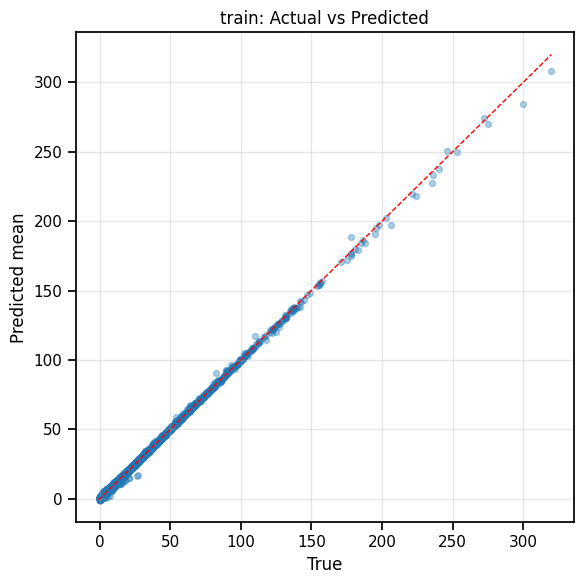

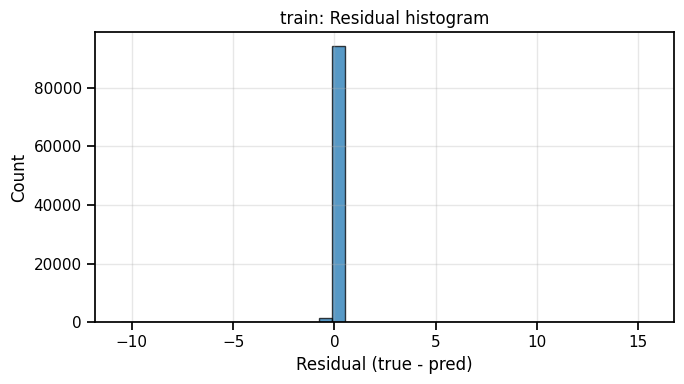

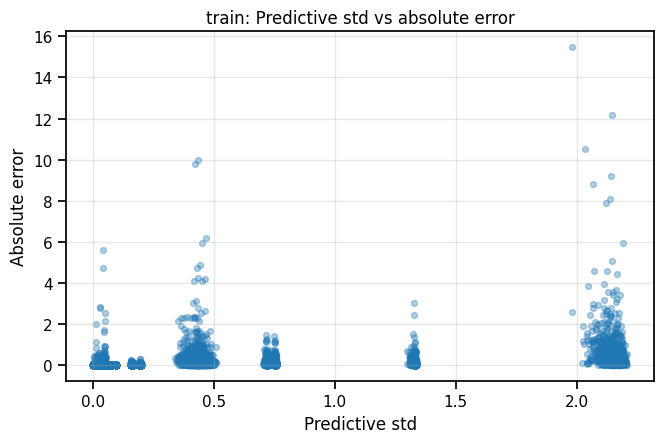

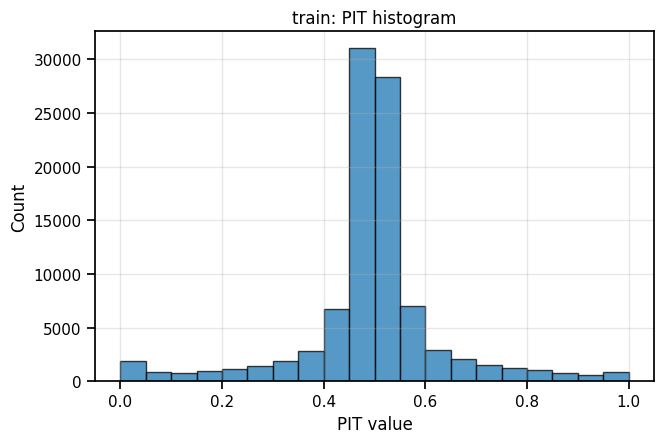

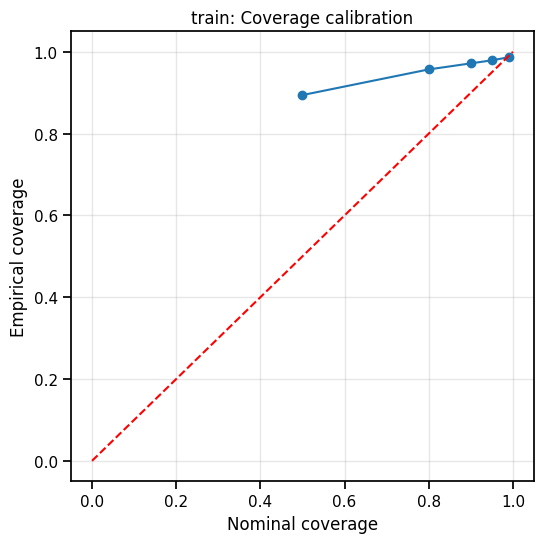

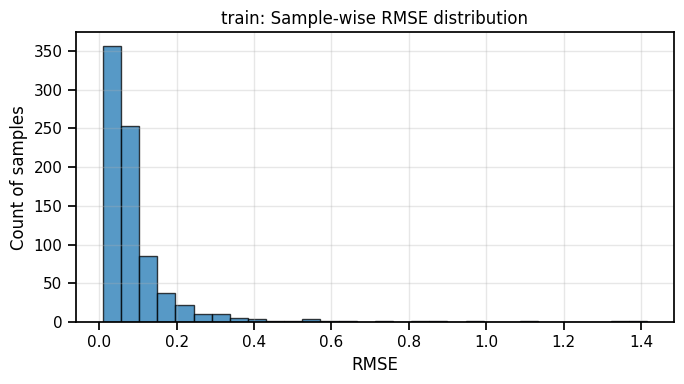

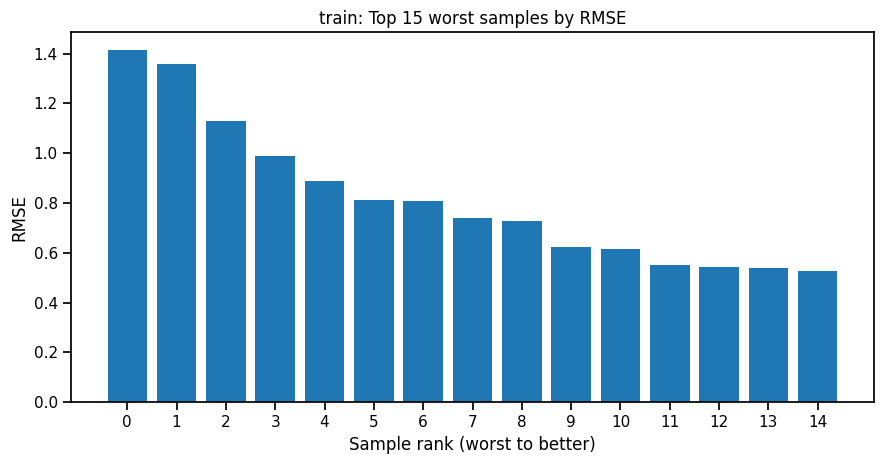

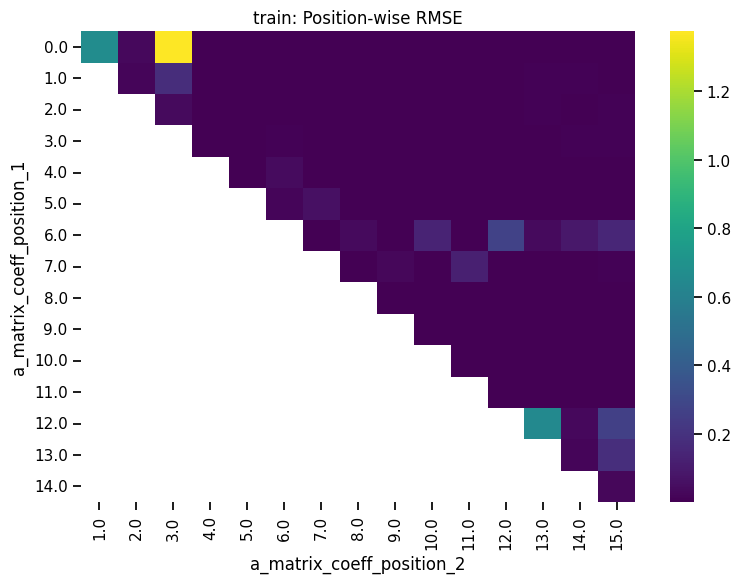

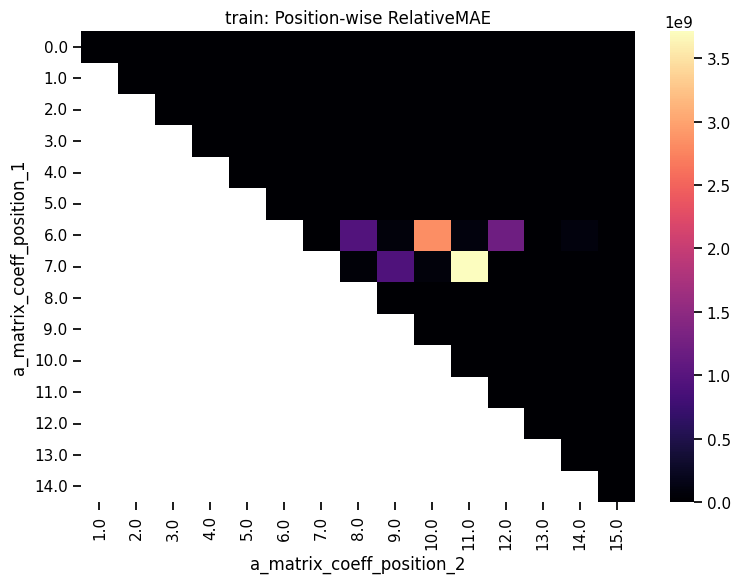

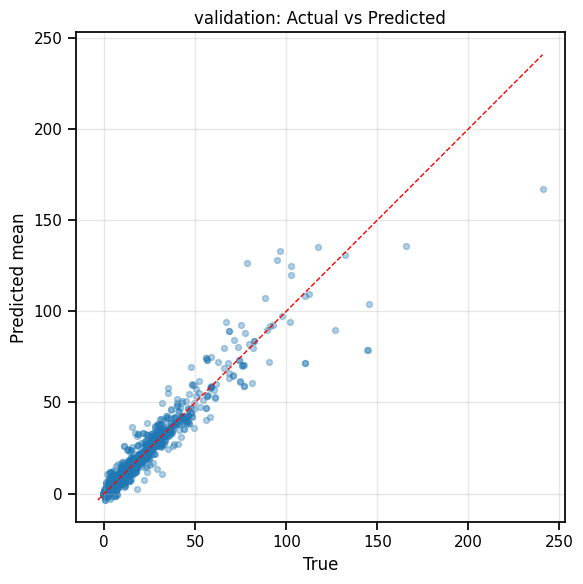

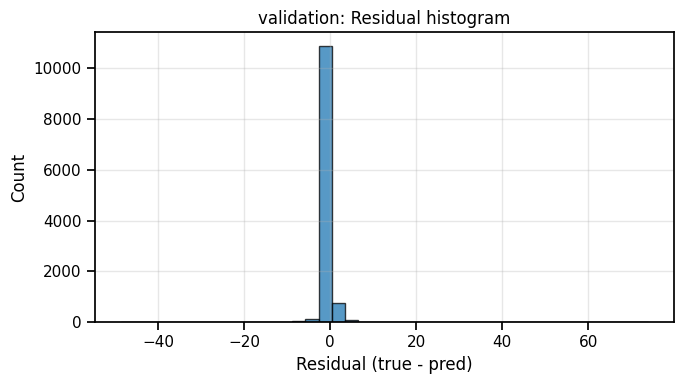

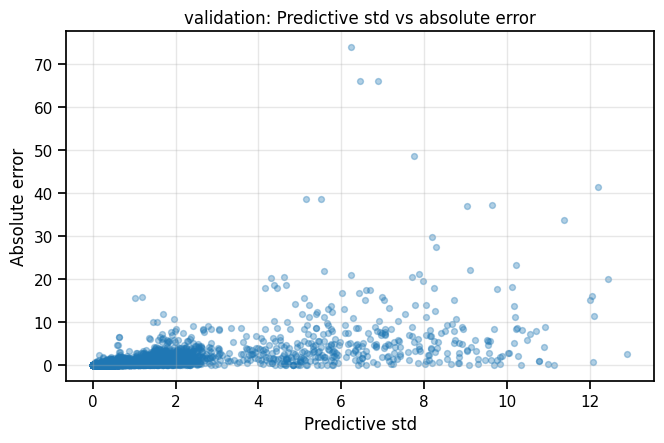

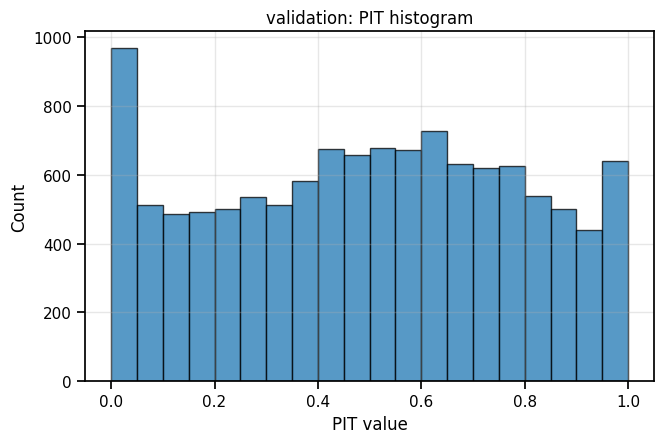

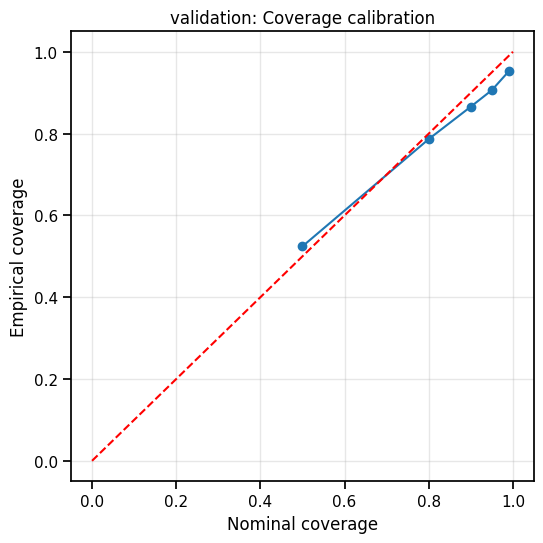

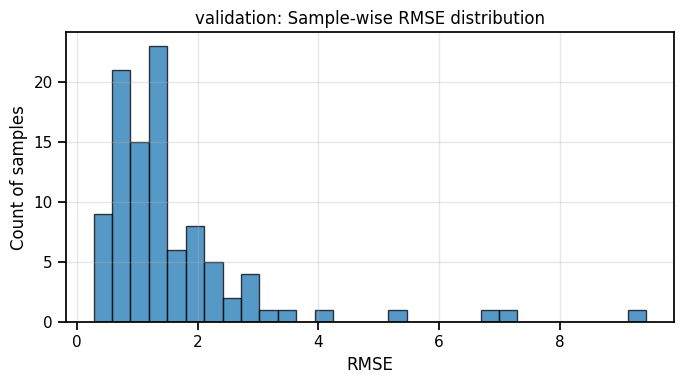

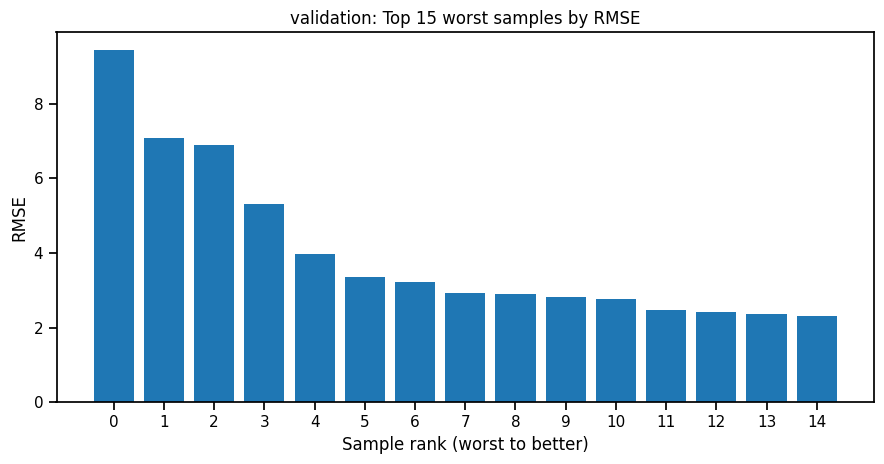

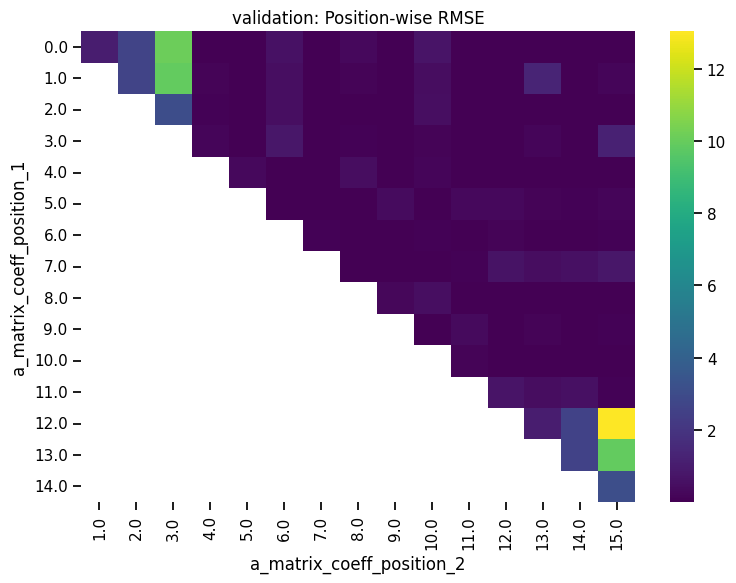

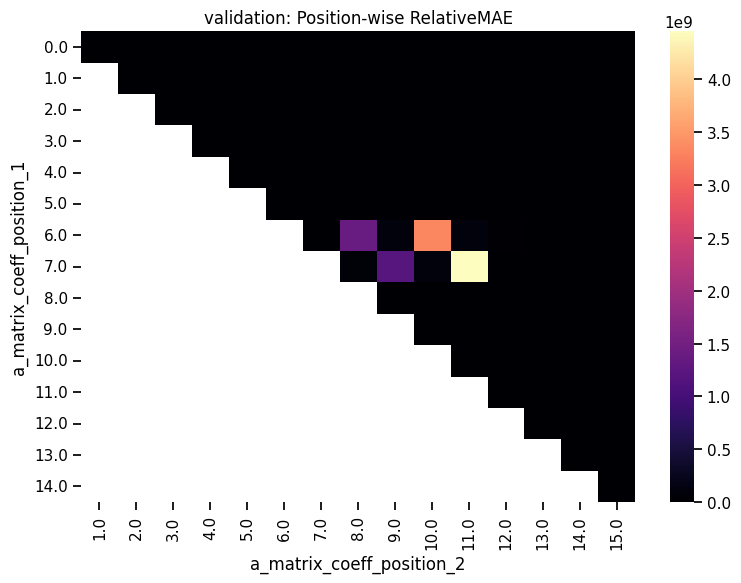

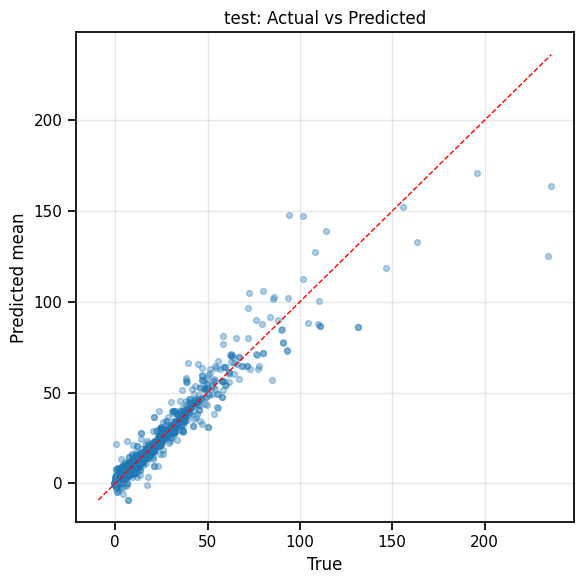

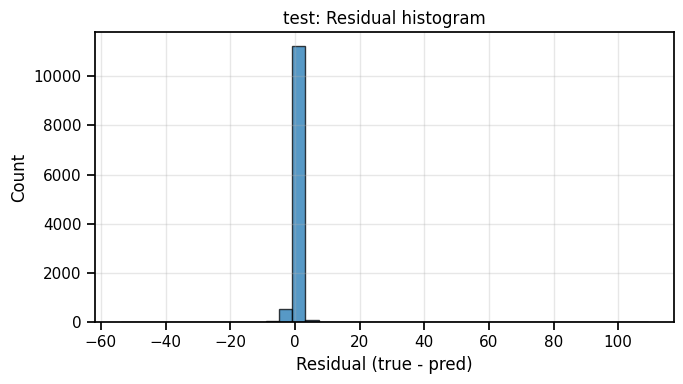

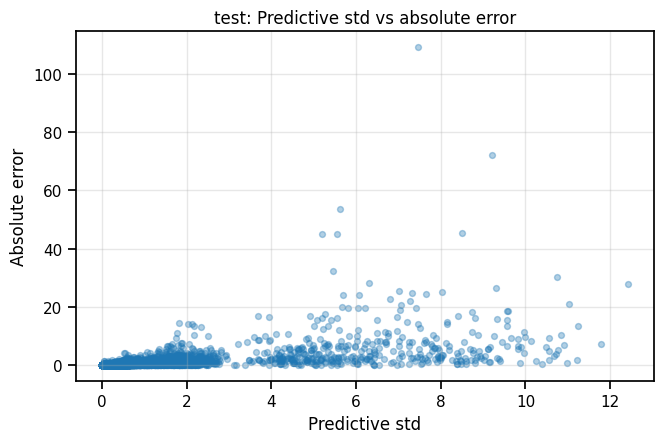

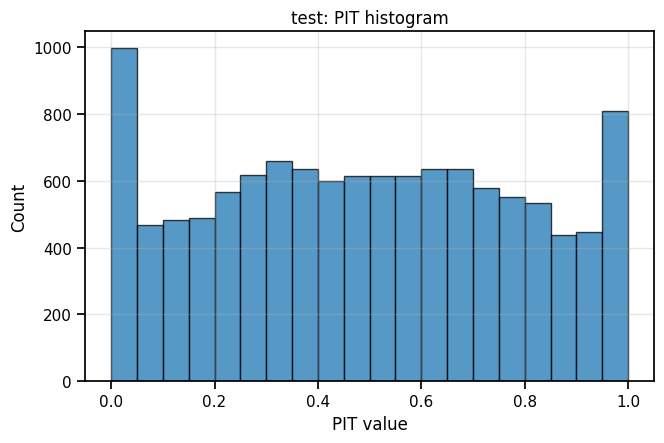

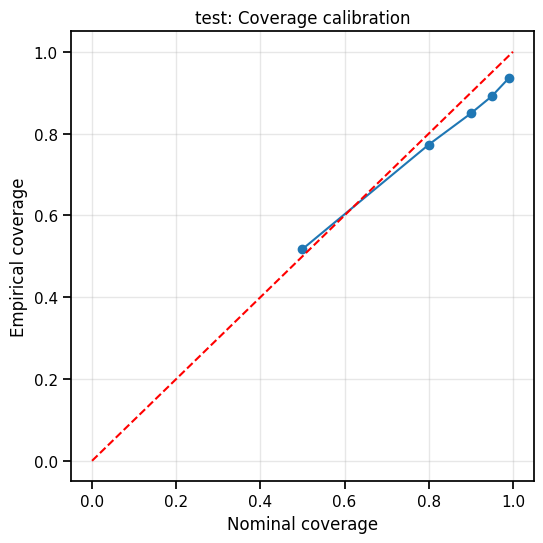

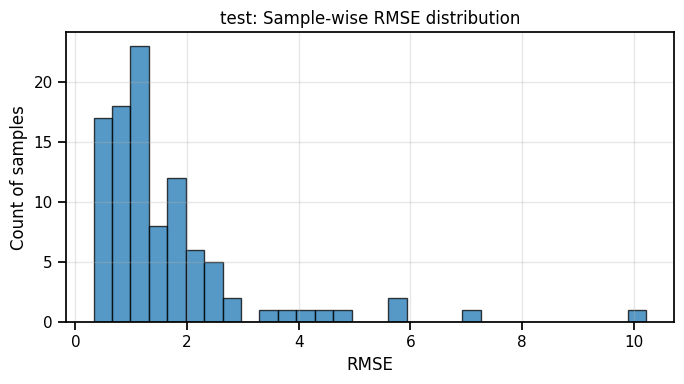

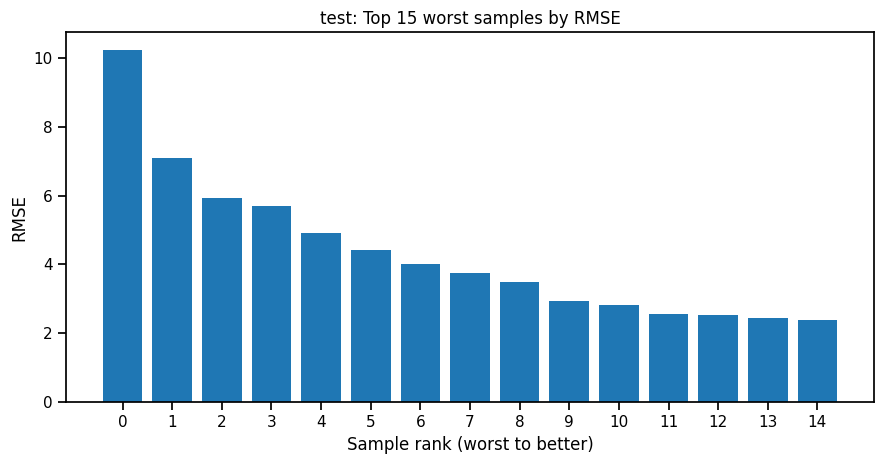

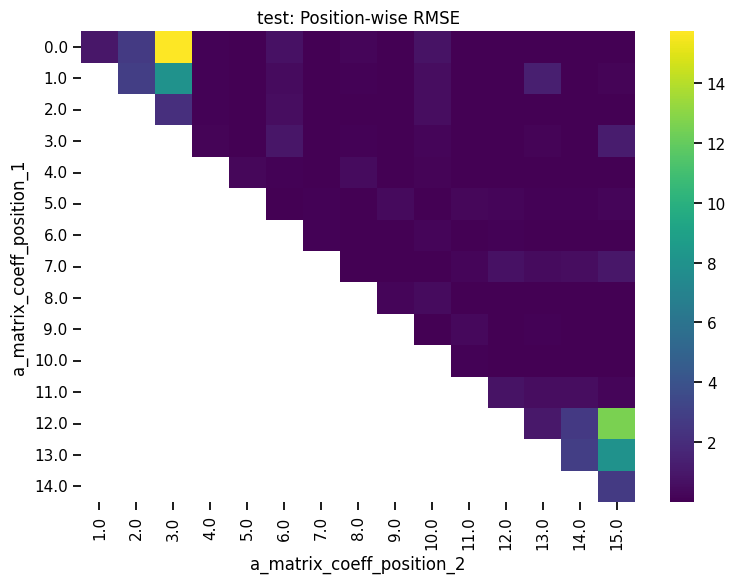

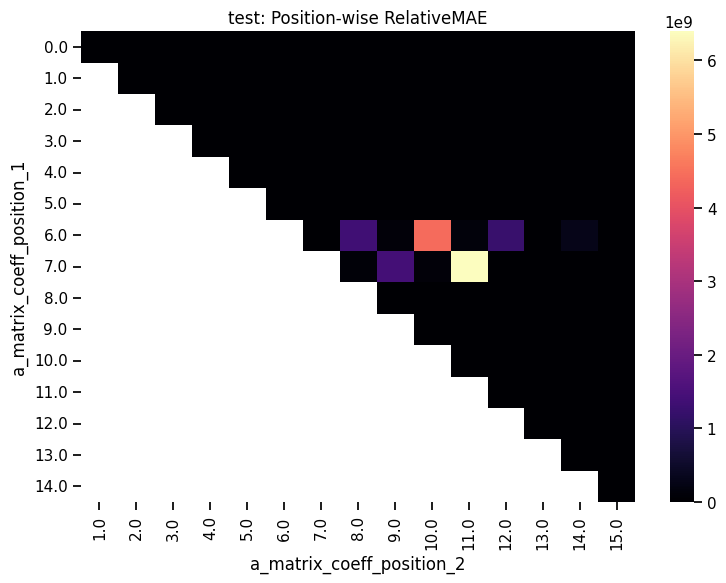

In [18]:
for split_name, df in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    plot_actual_vs_predicted(df, target_col, PRED_COL, split_name)
    plot_residual_hist(df, target_col, PRED_COL, split_name)
    plot_uncertainty_vs_abs_error(df, target_col, PRED_COL, PRED_STD_COL, split_name)
    plot_pit_hist(df, target_col, PRED_COL, PRED_STD_COL, split_name)
    plot_coverage_calibration(df, target_col, PRED_COL, PRED_STD_COL, split_name, levels=COVERAGE_LEVELS)

    plot_sample_metric_hist(results[split_name]['sample_metrics'], 'RMSE', split_name)
    plot_top_geometry_errors(results[split_name]['sample_metrics'], 'RMSE', split_name, top_k=15)

    plot_position_heatmap(results[split_name]['position_metrics'], position_cols, 'RMSE', split_name)
    plot_position_heatmap(results[split_name]['position_metrics'], position_cols, 'RelativeMAE', split_name, cmap='magma')

# Global Train Test Val Metrics

In [19]:

def global_metrics(y_true, y_pred):
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    import numpy as np

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }


In [20]:
err_metrics_train = global_metrics(y_true_train, y_pred_train)
err_metrics_test = global_metrics(y_true_test, y_pred_test)
err_metrics_val = global_metrics(y_true_val, y_pred_val)

In [21]:
print(err_metrics_train)
print(err_metrics_test)
print(err_metrics_val)

{'MAE': 0.01813931959066787, 'RMSE': 0.15897836675568883, 'R2': 0.9997409533572722}
{'MAE': 0.4295424261643907, 'RMSE': 2.211816615893113, 'R2': 0.9521958362521684}
{'MAE': 0.4184302764227076, 'RMSE': 2.0932682710143267, 'R2': 0.950749640233405}


# Sample_Wise Evaluation

In [22]:
def group_by_sample(df):
    df_copy = df.copy()

    grouped = df_copy.groupby(list(df.columns[:20]))  # first 20 = geometry

    results = []
    for _, group in grouped:
        results.append(group)

    return results


In [23]:
def sample_wise_metrics(grouped_samples):
    results = []

    for sample in grouped_samples:
        y_t = sample["a_matrix_coefficient"].values
        y_p = sample["a_matrix_coefficients_pred"].values

        results.append({
            "MAE": mean_absolute_error(y_t, y_p),
            "RMSE": np.sqrt(mean_squared_error(y_t, y_p)),
            "MAX_ERROR": np.max(np.abs(y_t - y_p))
        })

    return pd.DataFrame(results)

In [24]:

def summarize_sample_metrics(df_sample_metrics):
    return df_sample_metrics.describe()


In [25]:
def sample_shape_similarity(grouped_samples):
    import numpy as np

    corr_list = []

    for sample in grouped_samples:
        y_t = sample["y_true"].values
        y_p = sample["y_pred"].values

        if np.std(y_t) > 1e-8:
            corr = np.corrcoef(y_t, y_p)[0, 1]
        else:
            corr = np.nan

        corr_list.append(corr)

    return np.array(corr_list)